# Oficina de Machine Learning | Classificação: quais estudantes precisam de apoio?

**Projeto:** Tempo de jogo e desempenho acadêmico
**Base:** `Base_Original_GrupoGamingvsAcademicPerformance.csv` (8.000 estudantes, 14 variáveis)
**Alvo:** `desempenho`, criado a partir de `grades` — `Abaixo` se a nota for menor que 60, `Adequado` caso contrário
**Decisão que a previsão apoia:** no início do semestre, indicar quais estudantes devem entrar em um programa de
acompanhamento acadêmico (tutoria, monitoria, orientação de rotina de estudos).

Este notebook é a adaptação do notebook-oficina de classificação à base do projeto do grupo. Ele usa as mesmas regras
de limpeza e as mesmas variáveis criadas do notebook de regressão — a diferença está na **pergunta**: lá se estima
*quanto* o estudante vai tirar; aqui se decide *quem* recebe apoio.

## Roteiro
| Seção | Etapa | Pergunta | Etapa da aula 11 |
|---|---|---|---|
| 0 | Configuração e carregamento | De onde vêm os dados e o que se quer prever? | 1. Problema |
| 1 | Auditoria inicial da base | Há problemas de tipo, ausência, duplicata ou consistência? | 2. Dados |
| 2 | Divisão treino e teste | Como separar os dados antes de tomar decisões? | 5. Treino e teste |
| 3 | EDA inicial (no treino) | O que os dados mostram sobre o alvo? | 3. Variáveis |
| 4 | Pré-processamento | O que precisa ser transformado, e por quê? | 4. Preparação |
| 5 | EDA de validação | O pré-processamento fez o que deveria? Há vazamento? | 4. Preparação |
| 6 | Modelagem | Qual modelo e qual complexidade generalizam melhor? | 6. Treinamento |
| 7 | Avaliação final no teste | Qual o desempenho em dados nunca vistos? | 7. Previsões e 8. Avaliação |
| 8 | Análise de erros e interpretação | Onde o modelo erra e o que ele aprendeu? | 9. Interpretação |
| 9 | Conclusões | | |
| 10 | Desafios | | |
| 11 | Entrega: o que foi adaptado | | |

Sequência correta vista em aula: (1) limpar o que é regra fixa, (2) separar treino e teste, (3) ajustar as transformações só no treino, (4) escolher o modelo sem olhar o teste, (5) usar o teste uma única vez.

## Como este notebook se liga ao trabalho do grupo

| Etapa do projeto | Onde está |
|---|---|
| Preparação dos dados e EDA descritiva | `Analise_GrupoGamingvsAcademicPerformance.ipynb` (AV1) |
| Previsão da nota (regressão) | `oficina_ML_Regressao_GrupoGamingvsAcademicPerformance.ipynb` |
| **Previsão do risco de baixo desempenho (classificação)** | **este notebook** |

**Por que transformar a nota em duas classes?** Porque a decisão real é binária: o estudante entra ou não no programa
de acompanhamento. Um erro de 5 pontos na nota prevista (o que o modelo de regressão consegue) não diz nada sobre o
custo de deixar um estudante sem apoio. Aqui esse custo é explicitado em 0 e usado para escolher o limiar de alerta.

**O corte em 60** é a nota mínima de aprovação adotada pelo grupo como critério, por ser a mais comum no ensino
superior brasileiro. Ele é um parâmetro (`NOTA_DE_CORTE`) e pode ser trocado sem alterar o resto do notebook.

**Atenção ao vazamento:** como o alvo é construído a partir de `grades`, a própria coluna `grades` precisa ficar
**fora** das features — ela é o alvo disfarçado. Ela entra em `COLUNAS_FORA` e é usada na seção 5.3 justamente para
demonstrar como um vazamento se denuncia.

# 0. Configuração e carregamento

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
sns.set_style('whitegrid')
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')

## Parâmetros do problema

In [2]:
ALVO = 'desempenho'                       # criado em limpar(), a partir de grades
CLASSE_POSITIVA = 'Abaixo'                # o evento a detectar: nota abaixo da nota de corte
NOTA_DE_CORTE = 60                        # nota mínima de aprovação adotada pelo grupo
COLUNAS_FORA = ['student_id', 'grades']   # identificador e a nota, que é o próprio alvo disfarçado
PROPORCAO_TESTE = 0.25                    # parte da base guardada para a avaliação final
NOTA_MAXIMA = 100                         # teto da escala de notas, usado na limpeza

# Custos dos dois erros, em "vagas de tutoria" (1 unidade = custo de acompanhar um estudante por um semestre).
CUSTO_ACAO = 1    # custo de cada alerta: colocar o estudante no programa de acompanhamento
CUSTO_PERDA = 5   # custo de cada estudante em risco NÃO detectado: reprovação, repetição da disciplina e evasão
SEED = 42

**De onde vêm os custos.** Acompanhar um estudante que não precisava custa uma vaga de tutoria desperdiçada. Deixar
de acompanhar um estudante que reprova custa muito mais: a instituição refaz a disciplina, e o risco de evasão cresce.
O grupo estimou essa diferença em **cinco vezes**. O que importa não é o número exato, e sim a **razão** entre os dois
custos: ela define o limiar de equilíbrio (1/5 = 0,20) a partir do qual vale a pena alertar. A seção 6.5 mostra o
efeito dessa escolha, e o desafio 2 da seção 10 mostra o que acontece quando ela muda.

In [3]:
# A base do projeto é um arquivo local. O notebook procura o CSV nos caminhos abaixo.
# No Google Colab, envie o arquivo (ícone de pasta, à esquerda) ou descomente as três linhas finais.

CAMINHOS = ['dados/Base_Original_GrupoGamingvsAcademicPerformance.csv',
            'Base_Original_GrupoGamingvsAcademicPerformance.csv',
            '../dados/Base_Original_GrupoGamingvsAcademicPerformance.csv']
ARQUIVO_LOCAL = next((c for c in CAMINHOS if os.path.exists(c)), None)

# from google.colab import files
# enviados = files.upload()
# ARQUIVO_LOCAL = list(enviados.keys())[0]

if ARQUIVO_LOCAL is None:   # último recurso: baixar a base direto do Kaggle, como na AV1
    import glob, kagglehub
    ARQUIVO_LOCAL = glob.glob(os.path.join(kagglehub.dataset_download('aiexplorer77/gaming-vs-academic-performance'), '*.csv'))[0]
print('Arquivo:', ARQUIVO_LOCAL)

Arquivo: dados/Base_Original_GrupoGamingvsAcademicPerformance.csv


In [4]:
df_bruto = pd.read_csv(ARQUIVO_LOCAL, sep=None, engine='python')
print('Shape:', df_bruto.shape)
df_bruto.head()

Shape: (8000, 14)


,student_id,age,gender,gaming_hours,study_hours,sleep_hours,attendance,gaming_genre,social_activity,device_usage,reaction_time_ms,addiction_score,stress_level,grades
0,1,22,Male,7.230,8.780,6.960,91.440,FPS,3.250,9.360,235.840,14.690,Low,86.460
1,2,19,Male,0.070,8.720,7.630,63.630,Casual,1.020,3.210,328.710,2.470,Medium,98.230
2,3,23,Female,1.730,9.560,4.400,83.260,Casual,3.460,5.560,313.610,4.730,High,90.560
3,4,20,Female,6.620,1.680,7.830,75.040,RPG,1.460,11.780,241.840,14.540,Low,32.670
4,5,22,Female,5.360,5.830,5.550,65.570,FPS,1.010,8.230,249.310,12.480,Low,58.710


# 1. Auditoria inicial da base

In [5]:
df_bruto.info()
pd.DataFrame({'dtype': df_bruto.dtypes.astype(str), 'distintos': df_bruto.nunique(),
              'exemplo': [df_bruto[c].dropna().iloc[0] for c in df_bruto.columns]})

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   student_id        8000 non-null   int64  
 1   age               8000 non-null   int64  
 2   gender            8000 non-null   str    
 3   gaming_hours      8000 non-null   float64
 4   study_hours       8000 non-null   float64
 5   sleep_hours       8000 non-null   float64
 6   attendance        8000 non-null   float64
 7   gaming_genre      8000 non-null   str    
 8   social_activity   8000 non-null   float64
 9   device_usage      8000 non-null   float64
 10  reaction_time_ms  8000 non-null   float64
 11  addiction_score   8000 non-null   float64
 12  stress_level      8000 non-null   str    
 13  grades            8000 non-null   float64
dtypes: float64(9), int64(2), str(3)
memory usage: 875.1 KB


,dtype,distintos,exemplo
student_id,int64,8000,1
age,int64,9,22
gender,str,3,Male
gaming_hours,float64,801,7.230
study_hours,float64,901,8.780
sleep_hours,float64,501,6.960
attendance,float64,3472,91.440
gaming_genre,str,3,FPS
social_activity,float64,501,3.250
device_usage,float64,1202,9.360


**Leitura.** As 14 colunas chegam com o tipo certo: onze numéricas e três de texto (`gender`, `gaming_genre`,
`stress_level`), cada uma com três categorias. `student_id` tem 8.000 valores distintos, um por linha: é
identificador, não variável. Nenhuma conversão de tipo é necessária — diferente da base de exemplo da oficina, em que
`TotalCharges` vinha como texto.

A base **não traz uma coluna de alvo pronta**: não existe "aprovado/reprovado". Ela precisa ser construída a partir de
`grades`, o que é feito na seção 1.3.

## 1.2 Qualidade dos dados

In [6]:
# Completude: NaN e ausentes "disfarçados" (texto vazio, '?', 'NA'...), que o pandas não reconhece.
disfarcados = ['', ' ', '?', 'na', 'n/a', 'nan', 'none', 'null', '-']
tab_ausentes = pd.DataFrame({
    'NaN': df_bruto.isnull().sum(),
    '% NaN': (100 * df_bruto.isnull().mean()).round(2),
    'disfarçados': [df_bruto[c].astype(str).str.strip().str.lower().isin(disfarcados).sum()
                    if not pd.api.types.is_numeric_dtype(df_bruto[c]) else 0 for c in df_bruto.columns],
})
display(tab_ausentes)
print('Linhas duplicadas (iguais em todas as colunas):', df_bruto.duplicated().sum())
print('student_id repetidos:', df_bruto['student_id'].duplicated().sum())

,NaN,% NaN,disfarçados
student_id,0,0.000,0
age,0,0.000,0
gender,0,0.000,0
gaming_hours,0,0.000,0
study_hours,0,0.000,0
sleep_hours,0,0.000,0
attendance,0,0.000,0
gaming_genre,0,0.000,0
social_activity,0,0.000,0
device_usage,0,0.000,0


Linhas duplicadas (iguais em todas as colunas): 0
student_id repetidos: 0


In [7]:
texto = df_bruto.select_dtypes(exclude='number').drop(columns=COLUNAS_FORA, errors='ignore')
for c in texto.columns:
    print(f'{c:<14}', sorted(texto[c].astype(str).unique()))

# Faixas de validade das colunas desta base (regras do domínio, definidas na AV1).
soma_horas = df_bruto['gaming_hours'] + df_bruto['study_hours'] + df_bruto['sleep_hours']
regras = {
    'grades entre 0 e 100': ~df_bruto['grades'].between(0, NOTA_MAXIMA),
    'attendance entre 0 e 100': ~df_bruto['attendance'].between(0, 100),
    'addiction_score >= 0': ~(df_bruto['addiction_score'] >= 0),
    'age entre 10 e 100': ~df_bruto['age'].between(10, 100),
    'jogo + estudo + sono <= 24h por dia': soma_horas > 24,
}
display(pd.DataFrame({'violações': {k: int(v.sum()) for k, v in regras.items()},
                      '% da base': {k: round(100 * v.mean(), 2) for k, v in regras.items()}}))

# Quantos estudantes ficariam de cada lado da nota de corte, antes da limpeza:
print(f'Abaixo de {NOTA_DE_CORTE}: {(df_bruto["grades"] < NOTA_DE_CORTE).mean():.1%} dos estudantes')

gender         ['Female', 'Male', 'Other']
gaming_genre   ['Casual', 'FPS', 'RPG']
stress_level   ['High', 'Low', 'Medium']


,violações,% da base
grades entre 0 e 100,134,1.680
attendance entre 0 e 100,0,0.000
addiction_score >= 0,107,1.340
age entre 10 e 100,0,0.000
jogo + estudo + sono <= 24h por dia,98,1.230


Abaixo de 60: 39.1% dos estudantes


**Leitura.** Não há ausentes (nem NaN nem disfarçados), não há duplicatas e `student_id` não se repete. As categorias
são consistentes, sem variações de grafia.

Os problemas estão nas **faixas de validade**, e são os mesmos três casos identificados na AV1: 134 notas acima de 100
(1,68%), 107 escores de dependência negativos (1,34%) e 98 estudantes com mais de 24 horas somadas de jogo, estudo e
sono (1,23%). Cada um afeta menos de 2% da base e nenhum é erro de digitação isolado: são artefatos da **simulação**
que gerou os dados.

O corte em 60 produz uma base **moderadamente desbalanceada**: cerca de 39% dos estudantes ficam abaixo da nota de
corte. É um desbalanceamento bem menor que o da base de exemplo da oficina (26,5% de cancelamentos) e não exige
tratamento especial — basta não usar a acurácia sozinha como métrica.

## 1.3 Limpeza determinística

In [8]:
def limpar(d):
    d = d.copy()
    # Regras gerais (servem para qualquer base): texto sem espaços nas pontas e vazio como ausente.
    for c in d.select_dtypes(exclude='number').columns:
        d[c] = d[c].astype(str).str.strip().replace({'': np.nan, 'nan': np.nan, 'None': np.nan})
    d = d.drop_duplicates()

    # Regras desta base (as mesmas decisões tomadas na AV1):
    d['grades'] = d['grades'].clip(0, NOTA_MAXIMA)             # 134 notas acima de 100 -> limitadas ao teto da escala
    d['addiction_score'] = d['addiction_score'].clip(lower=0)  # 107 escores negativos -> limitados a zero
    horas = d['gaming_hours'] + d['study_hours'] + d['sleep_hours']
    d = d[horas <= 24]                                         # 98 dias de mais de 24h -> removidos
    d = d[d['grades'].notna()]                                 # sem nota não dá para definir o alvo

    # Construção do alvo: a decisão é binária, então a nota vira duas classes.
    d[ALVO] = np.where(d['grades'] < NOTA_DE_CORTE, 'Abaixo', 'Adequado')
    return d


df = limpar(df_bruto)
y = (df[ALVO] == CLASSE_POSITIVA).astype(int)
X = df.drop(columns=[ALVO] + COLUNAS_FORA)
print(f'Linhas: {len(df_bruto)} -> {len(df)} | features: {X.shape[1]} | classe positiva: {ALVO} = {CLASSE_POSITIVA!r} (y = 1)')
print(f'Taxa de estudantes abaixo da nota de corte: {y.mean():.1%}')
print('Ausentes depois da limpeza:', int(X.isnull().sum().sum()))
print('Features usadas:', list(X.columns))

Linhas: 8000 -> 7902 | features: 12 | classe positiva: desempenho = 'Abaixo' (y = 1)
Taxa de estudantes abaixo da nota de corte: 39.6%
Ausentes depois da limpeza: 0
Features usadas: ['age', 'gender', 'gaming_hours', 'study_hours', 'sleep_hours', 'attendance', 'gaming_genre', 'social_activity', 'device_usage', 'reaction_time_ms', 'addiction_score', 'stress_level']


**Por que limitar em vez de remover?** Nos dois primeiros casos sabemos qual é o valor correto mais próximo (o teto da
escala e o zero). No terceiro não é possível saber qual das três horas está errada, então essas 98 linhas saem.
A base de trabalho fica com **7.902 estudantes**, a mesma quantidade da base pré-processada da AV1.

Repare na lista de features: `grades` **não está lá**. Ela saiu junto com `student_id` em `COLUNAS_FORA`, porque o
alvo foi construído a partir dela. Mantê-la daria um modelo com 100% de acerto e nenhuma utilidade.

# 2. Divisão treino e teste

In [9]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=PROPORCAO_TESTE, stratify=y, random_state=SEED)
print(f'Treino: {len(X_treino)} linhas | Teste: {len(X_teste)} linhas')
pd.DataFrame({'treino': y_treino.value_counts(normalize=True), 'teste': y_teste.value_counts(normalize=True)}).round(3)

Treino: 5926 linhas | Teste: 1976 linhas

,treino,teste
desempenho,,
0,0.604,0.604
1,0.396,0.396


A divisão é **estratificada** (`stratify=y`): treino e teste ficam com a mesma proporção de estudantes abaixo da nota
de corte (39,6% nos dois). Sem isso, uma divisão aleatória poderia deixar os conjuntos com taxas diferentes e tornar
as métricas incomparáveis. O teste fica guardado e é usado uma única vez, na seção 7.

# 3. EDA inicial (no treino)

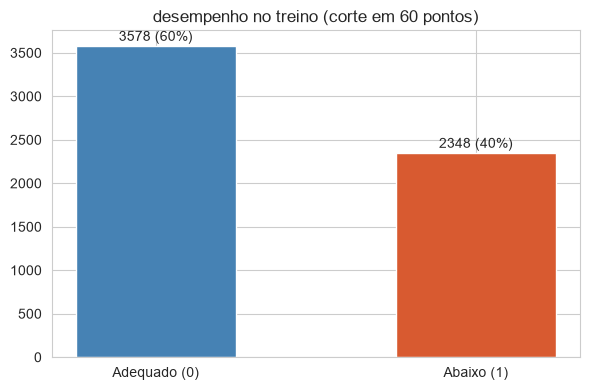

Referência: responder sempre a classe mais frequente acerta 60.4% e encontra 0% dos casos positivos.


In [10]:
eda = X_treino.assign(alvo=y_treino.values)
NUM = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
CAT = [c for c in X.columns if c not in NUM]
cont = y_treino.value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(['Adequado (0)', f'{CLASSE_POSITIVA} (1)'], cont.values, color=['steelblue', '#D85A30'], width=0.5)
for j, v in enumerate(cont.values):
    plt.text(j, v + len(eda) * 0.01, f'{v} ({v / len(eda):.0%})', ha='center')
plt.title(f'{ALVO} no treino (corte em {NOTA_DE_CORTE} pontos)')
plt.tight_layout()
plt.show()
print(f'Referência: responder sempre a classe mais frequente acerta {max(y_treino.mean(), 1 - y_treino.mean()):.1%} e encontra 0% dos casos positivos.')

**Leitura.** No treino, **2.348 estudantes (39,6%) ficam abaixo de 60** e 3.578 (60,4%) ficam acima. A referência a
superar é "responder sempre *Adequado*": ela acerta **60,4%** das vezes e, apesar disso, é **inútil** — encontra zero
estudantes em risco e, portanto, não indica ninguém para o programa de acompanhamento.

É por isso que a acurácia não pode ser a única métrica. O que interessa aqui é o **recall**: de todos os estudantes
que de fato ficarão abaixo da nota de corte, quantos o modelo consegue identificar a tempo.

## 3.2 Variáveis numéricas

,n,média,mediana,desvio padrão,mín,Q1,Q3,máx,IQR,assimetria,outliers (IQR),% outliers
age,"5,926.000",20.010,20.000,2.600,16.000,18.000,22.000,24.000,4.000,-0.020,0.000,0.000
gaming_hours,"5,926.000",4.040,4.090,2.290,0.000,2.090,5.980,8.000,3.890,-0.040,0.000,0.000
study_hours,"5,926.000",5.430,5.420,2.560,1.000,3.230,7.590,10.000,4.360,0.030,0.000,0.000
sleep_hours,"5,926.000",6.460,6.450,1.440,4.000,5.190,7.670,9.000,2.480,0.040,0.000,0.000
attendance,"5,926.000",79.980,79.840,11.620,60.000,69.900,90.320,100.000,20.420,0.010,0.000,0.000
social_activity,"5,926.000",2.520,2.510,1.440,0.000,1.290,3.770,5.000,2.480,-0.000,0.000,0.000
device_usage,"5,926.000",7.540,7.540,2.710,1.160,5.510,9.550,13.910,4.040,0.010,0.000,0.000
reaction_time_ms,"5,926.000",271.610,271.130,29.130,197.690,248.080,295.160,347.870,47.080,0.050,0.000,0.000
addiction_score,"5,926.000",9.850,9.870,4.970,0.000,5.910,13.680,23.010,7.770,0.010,0.000,0.000


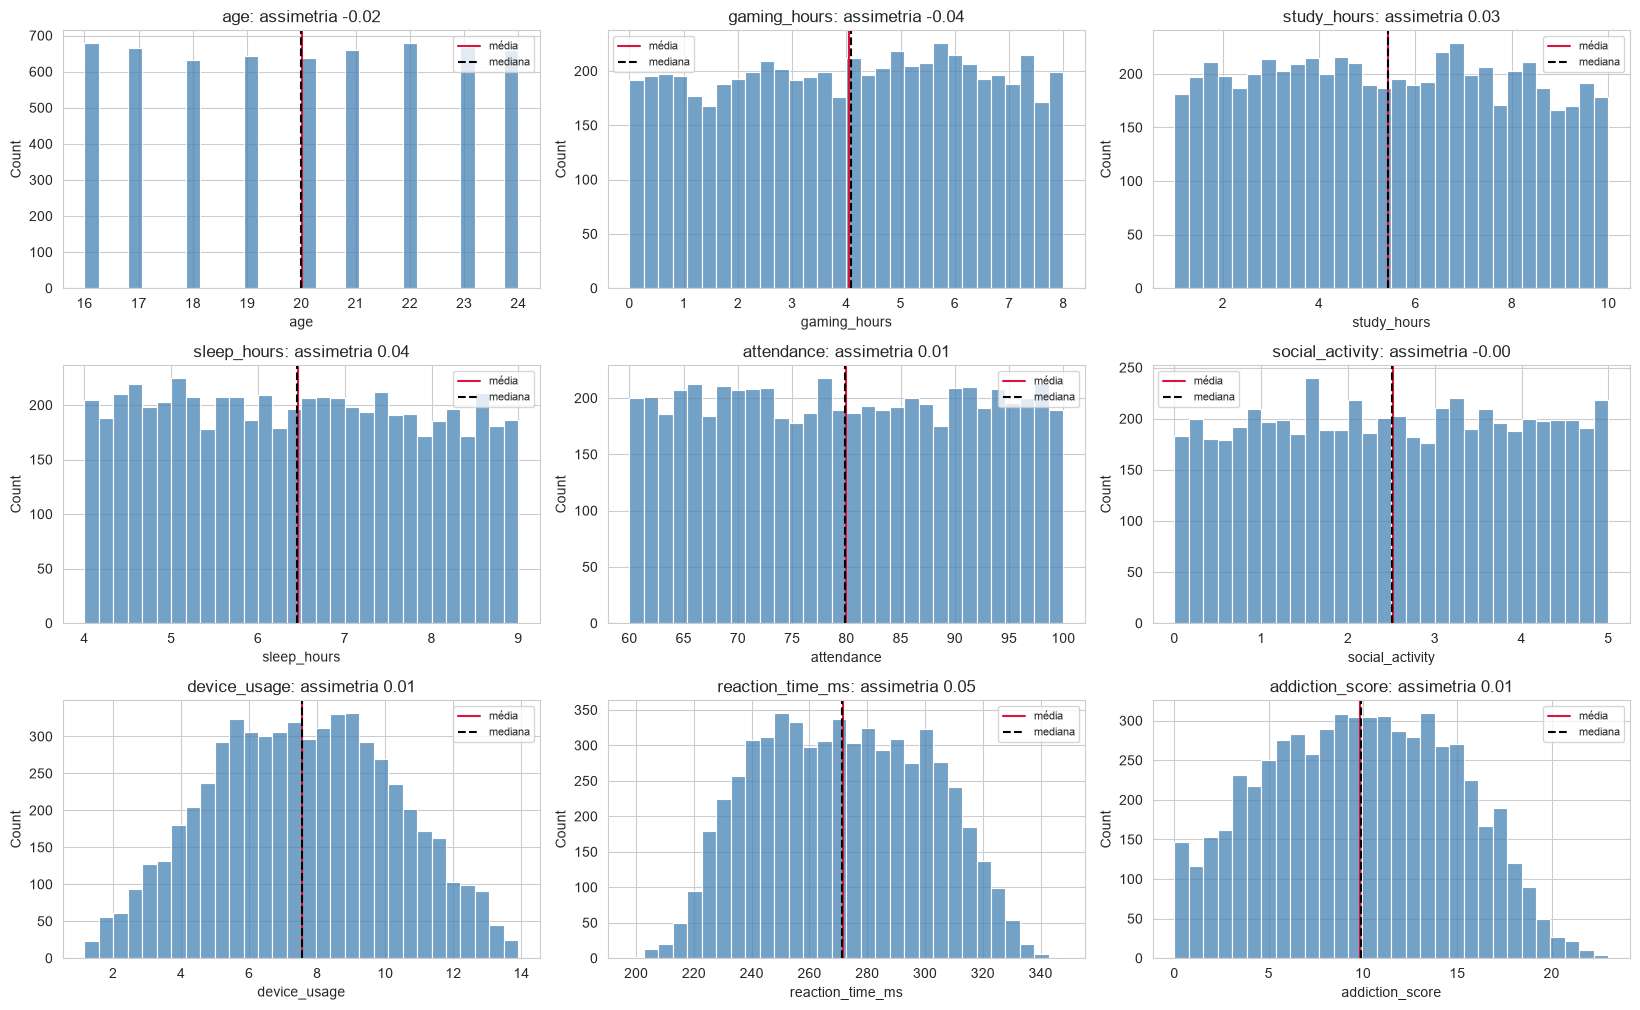

In [11]:
def resumo_numerico(dados):
    # Centro, dispersão, forma e extremos (medidas vistas na aula de EDA).
    linhas = {}
    for c in dados.columns:
        x = dados[c].dropna()
        q1, q3 = x.quantile([0.25, 0.75])
        iqr = q3 - q1
        n_out = int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum())
        linhas[c] = {'n': len(x), 'média': x.mean(), 'mediana': x.median(), 'desvio padrão': x.std(),
                     'mín': x.min(), 'Q1': q1, 'Q3': q3, 'máx': x.max(), 'IQR': iqr,
                     'assimetria': x.skew(), 'outliers (IQR)': n_out, '% outliers': 100 * n_out / len(x)}
    return pd.DataFrame(linhas).T


def outliers_iqr(x):
    # Regra do boxplot: fora de [Q1 - 1,5*IQR ; Q3 + 1,5*IQR]
    q1, q3 = x.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)


def outliers_desvio(x, k=3):
    # Regra do desvio padrão: mais de k desvios da média (z-score)
    return ((x - x.mean()) / x.std()).abs() > k


display(resumo_numerico(eda[NUM]).round(2))
colunas = 3
linhas = int(np.ceil(len(NUM) / colunas))
fig, axes = plt.subplots(linhas, colunas, figsize=(5.5 * colunas, 3.4 * linhas), squeeze=False)
for ax, c in zip(axes.flat, NUM):
    sns.histplot(eda[c].dropna(), bins=30, ax=ax, color='steelblue')
    ax.axvline(eda[c].mean(), color='crimson', lw=1.5, label='média')
    ax.axvline(eda[c].median(), color='black', ls='--', lw=1.5, label='mediana')
    ax.set_title(f'{c}: assimetria {eda[c].skew():.2f}')
    ax.legend(fontsize=8)
for ax in axes.flat[len(NUM):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

**Leitura.** Todas as nove numéricas têm assimetria praticamente zero (entre −0,04 e +0,04) e média igual à mediana.
`gaming_hours` (0 a 8h), `study_hours` (1 a 10h), `sleep_hours` (4 a 9h), `attendance` (60 a 100%),
`social_activity` (0 a 5) e `age` (16 a 24) são **uniformes**, com cortes exatos nos extremos — assinatura de dados
simulados. `device_usage`, `reaction_time_ms` e `addiction_score` têm forma de sino, sinal de que foram geradas a
partir das outras. Nenhuma precisa de transformação de escala, e a árvore de decisão não exigiria isso de qualquer forma.

## 3.3 Variáveis categóricas

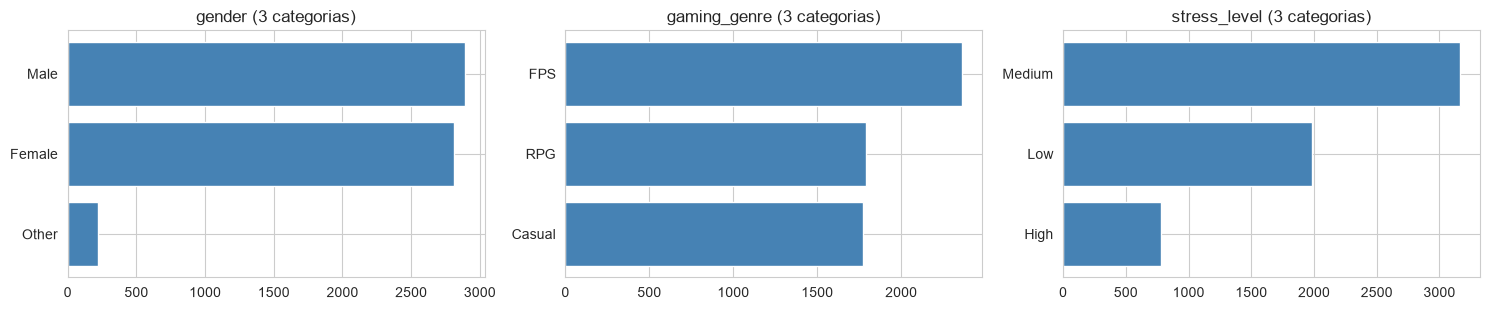

,proporção no treino
gender,
Male,0.488
Female,0.475
Other,0.037


,proporção no treino
gaming_genre,
FPS,0.399
RPG,0.302
Casual,0.299


,proporção no treino
stress_level,
Medium,0.534
Low,0.334
High,0.131


In [12]:
fig, axes = plt.subplots(1, len(CAT), figsize=(5 * len(CAT), 3.2), squeeze=False)
for ax, c in zip(axes[0], CAT):
    freq = eda[c].value_counts().head(10)
    ax.barh(freq.index.astype(str)[::-1], freq.values[::-1], color='steelblue')
    ax.set_title(f'{c} ({eda[c].nunique()} categorias)')
plt.tight_layout()
plt.show()
for c in CAT:
    display(eda[c].value_counts(normalize=True).round(3).to_frame('proporção no treino'))

**Leitura.** `gender` e `gaming_genre` são equilibradas (`Male` 48,8%, `Female` 47,5%, `Other` 3,7%; os três gêneros
de jogo entre 30% e 40%). `stress_level` é a única desbalanceada: `Medium` 53,4%, `Low` 33,4% e `High` 13,1%.
Nenhuma categoria tem menos de 30 observações, então todas podem ser usadas e não há categorias raras para agrupar.

## 3.4 Outliers: erro ou caso real?

In [13]:
display(pd.DataFrame({'outliers (IQR)': {c: int(outliers_iqr(eda[c].dropna()).sum()) for c in NUM},
                      'outliers (|z| > 3)': {c: int(outliers_desvio(eda[c].dropna()).sum()) for c in NUM}}))

,outliers (IQR),outliers (|z| > 3)
age,0,0
gaming_hours,0,0
study_hours,0,0
sleep_hours,0,0
attendance,0,0
social_activity,0,0
device_usage,0,0
reaction_time_ms,0,0
addiction_score,0,0


**Leitura.** Depois da limpeza da seção 1.3, **nenhuma variável tem outlier pela regra do IQR** e apenas
`reaction_time_ms` tem um valor além de 3 desvios da média. É consequência das distribuições uniformes (que não
produzem caudas) e do tratamento já feito nos valores impossíveis. Nada mais precisa ser removido.

## 3.5 Numéricas e o alvo

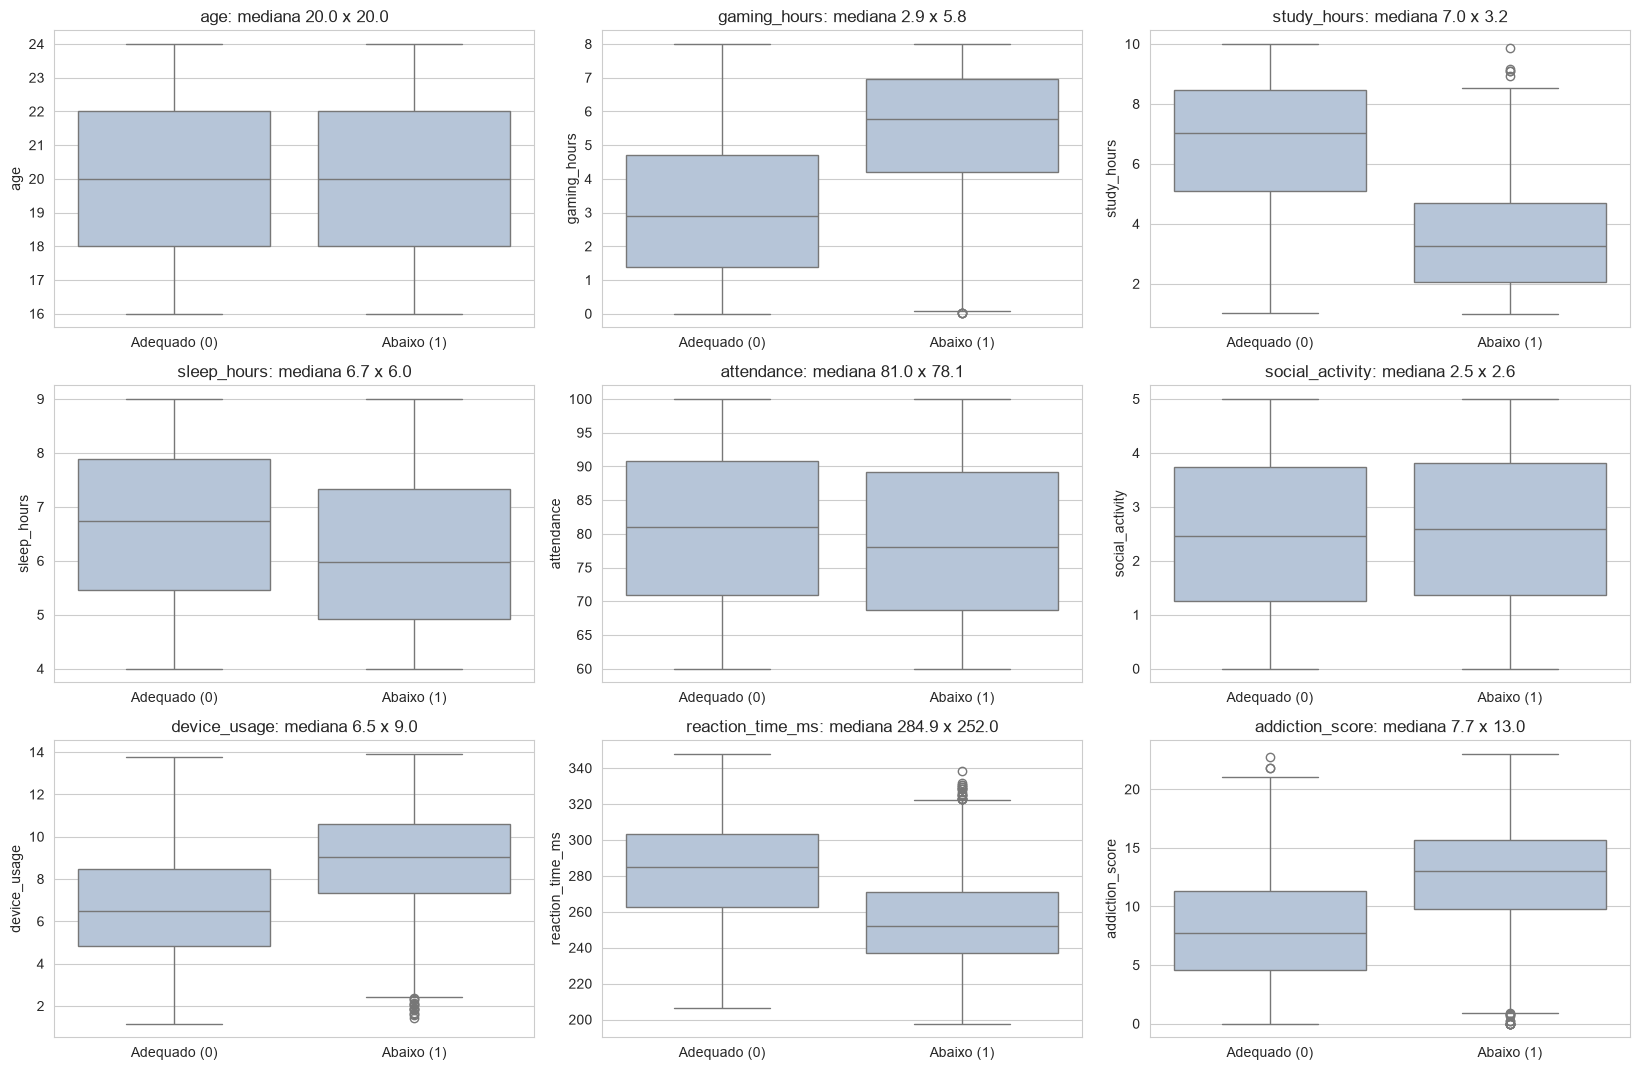

,Pearson com o alvo (1 = abaixo do corte)
study_hours,-0.606
gaming_hours,0.477
reaction_time_ms,-0.448
addiction_score,0.436
device_usage,0.404
sleep_hours,-0.171
attendance,-0.083
social_activity,0.025
age,-0.004


In [14]:
colunas = 3
linhas = int(np.ceil(len(NUM) / colunas))
fig, axes = plt.subplots(linhas, colunas, figsize=(5.5 * colunas, 3.6 * linhas), squeeze=False)
for ax, c in zip(axes.flat, NUM):
    sns.boxplot(data=eda, x='alvo', y=c, ax=ax, color='lightsteelblue')
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Adequado (0)', f'{CLASSE_POSITIVA} (1)'])
    ax.set_title(f'{c}: mediana {eda.loc[eda.alvo == 0, c].median():,.1f} x {eda.loc[eda.alvo == 1, c].median():,.1f}')
    ax.set_xlabel('')
for ax in axes.flat[len(NUM):]:
    ax.axis('off')
plt.tight_layout()
plt.show()
eda[NUM].corrwith(eda['alvo']).sort_values(key=abs, ascending=False).round(3).to_frame('Pearson com o alvo (1 = abaixo do corte)')

**Leitura.** Quem fica abaixo da nota de corte **estuda bem menos e joga bem mais**:

| Variável | Mediana de quem fica adequado | Mediana de quem fica abaixo | Pearson com o alvo |
|---|---|---|---|
| `study_hours` | 7,03 h | **3,25 h** | **−0,606** |
| `gaming_hours` | 2,89 h | **5,76 h** | **+0,477** |
| `reaction_time_ms` | 284,9 ms | 252,0 ms | −0,448 |
| `addiction_score` | 7,74 | 13,03 | +0,436 |
| `device_usage` | 6,46 h | 9,04 h | +0,404 |
| `sleep_hours` | 6,74 h | 5,98 h | −0,171 |
| `attendance` | 80,99% | 78,08% | −0,083 |
| `social_activity` | 2,46 | 2,59 | +0,025 |
| `age` | 20,0 | 20,0 | −0,004 |

As horas de estudo caem pela metade e as de jogo quase dobram. Os boxplots mostram sobreposição parcial entre as duas
classes nas duas variáveis — então nenhuma delas sozinha resolve o problema, mas as duas juntas separam bem.
`attendance`, `social_activity` e `age` praticamente não distinguem os grupos.

## 3.6 Categóricas e o alvo: taxa por categoria

,amplitude da taxa
stress_level,0.656
gender,0.032
gaming_genre,0.013


,n,taxa
stress_level,,
High,779,0.068
Medium,3165,0.272
Low,1982,0.724


,n,taxa
gender,,
Other,222,0.374
Male,2890,0.389
Female,2814,0.405


,n,taxa
gaming_genre,,
FPS,2365,0.392
Casual,1773,0.394
RPG,1788,0.404


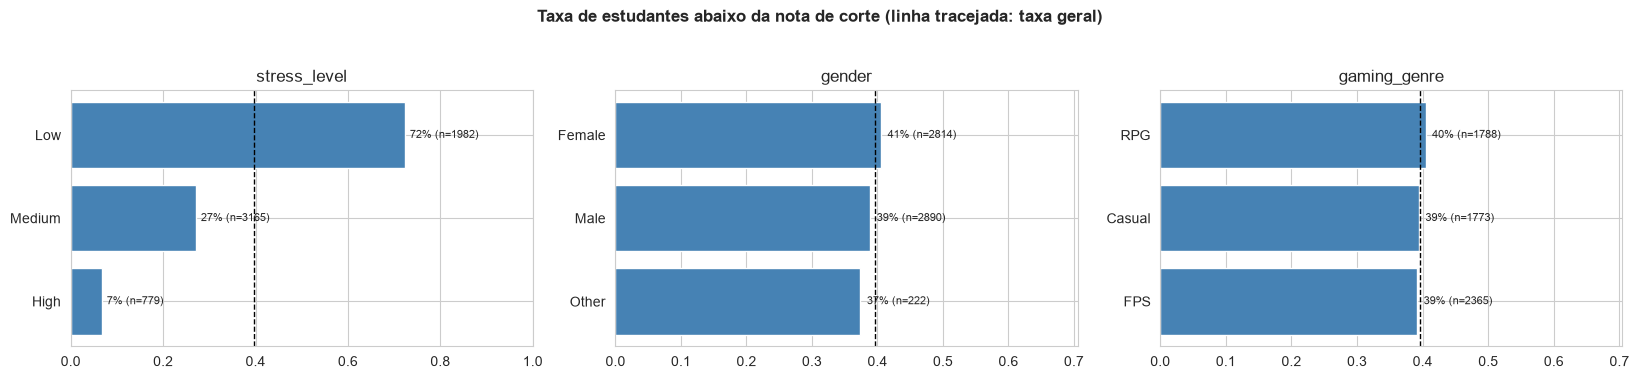

In [15]:
def taxa_por(col):
    return eda.groupby(col, observed=True)['alvo'].agg(n='count', taxa='mean').sort_values('taxa')


amplitude = pd.Series({c: taxa_por(c).query('n >= 30')['taxa'].agg(lambda s: s.max() - s.min()) for c in CAT}).sort_values(ascending=False)
display(amplitude.round(3).to_frame('amplitude da taxa'))
for c in amplitude.index:
    display(taxa_por(c).round(3))

fig, axes = plt.subplots(1, len(CAT), figsize=(5.5 * len(CAT), 3.6), squeeze=False)
for ax, c in zip(axes[0], amplitude.index):
    t = taxa_por(c)
    ax.barh(t.index.astype(str), t['taxa'], color='steelblue')
    ax.axvline(eda['alvo'].mean(), color='black', ls='--', lw=1)
    for j, (tx, n) in enumerate(zip(t['taxa'], t['n'])):
        ax.text(tx + 0.01, j, f'{tx:.0%} (n={n})', va='center', fontsize=8)
    ax.set(xlim=(0, min(1, t['taxa'].max() + 0.3)), title=c)
plt.suptitle('Taxa de estudantes abaixo da nota de corte (linha tracejada: taxa geral)', y=1.04, fontweight='bold')
plt.tight_layout()
plt.show()

**Leitura.** Só uma das três categóricas separa o alvo: `stress_level`, com **65,6 pontos percentuais** de amplitude —
e no sentido oposto ao esperado:

| `stress_level` | n | % abaixo da nota de corte |
|---|---|---|
| High | 779 | **6,8%** |
| Medium | 3.165 | 27,2% |
| Low | 1.982 | **72,4%** |

Quem declara estresse **baixo** tem 72% de chance de ficar abaixo de 60; quem declara estresse **alto**, apenas 7%.
A AV1 já havia marcado essa associação invertida como pendente. A explicação aparece em 3.7: estresse alto se
concentra entre quem estuda muitas horas — ele é **marcador de esforço**, não causa de bom desempenho.
Na prática isso é um alerta: se o programa de acompanhamento usasse "estresse declarado" como critério de triagem,
ele chamaria exatamente os estudantes errados.

`gender` (3,2 pontos) e `gaming_genre` (1,3 ponto) são irrelevantes: a taxa de risco é praticamente a mesma em todas
as categorias. **O que importa é quanto se joga, não o que se joga nem quem joga.**

## 3.7 Relações entre numéricas e discretização

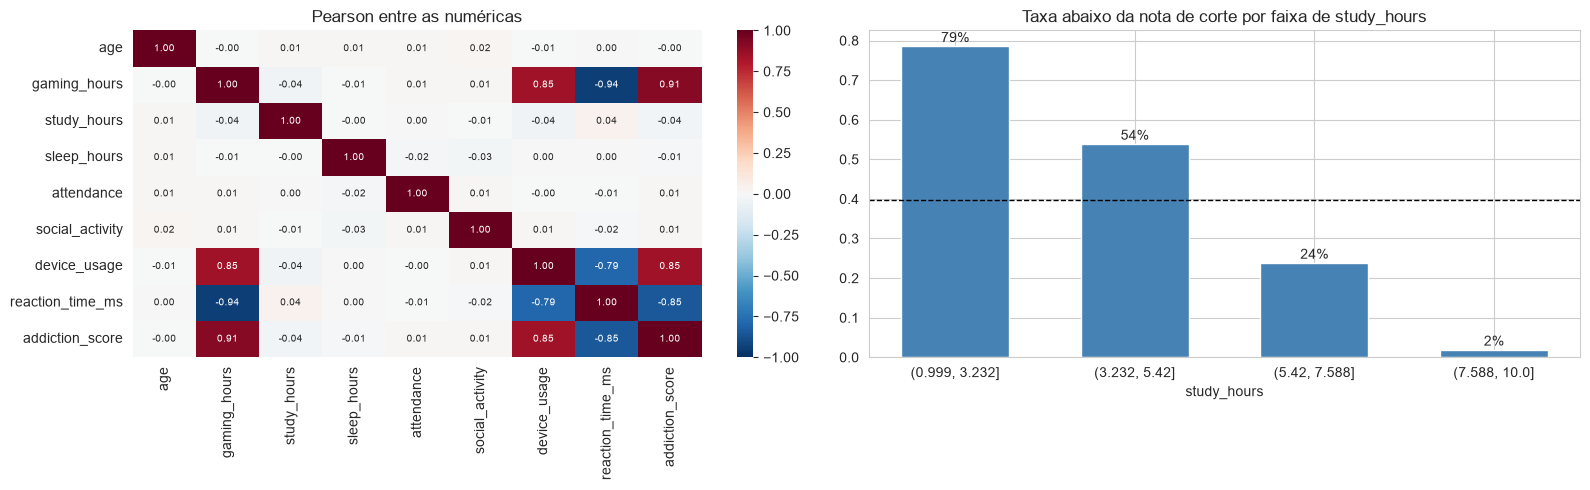

Correlação de gaming_hours com as demais numéricas:


,Pearson
reaction_time_ms,-0.940
addiction_score,0.910
device_usage,0.850
study_hours,-0.040
social_activity,0.010
attendance,0.010
sleep_hours,-0.010
age,-0.000


Distribuição de stress_level por faixa de study_hours (% da linha):


stress_level,High,Low,Medium
study_hours,,,
"(0.999, 3.232]",0.000,39.700,60.300
"(3.232, 5.42]",0.000,40.700,59.300
"(5.42, 7.588]",11.900,33.200,54.900
"(7.588, 10.0]",40.700,20.200,39.100


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(eda[NUM].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            ax=axes[0], annot_kws={'size': 7})
axes[0].set_title('Pearson entre as numéricas')
principal = eda[NUM].corrwith(eda['alvo']).abs().idxmax()
faixas = pd.qcut(eda[principal], 4, duplicates='drop')
t = eda.groupby(faixas, observed=True)['alvo'].agg(n='count', taxa='mean')
axes[1].bar(t.index.astype(str), t['taxa'], color='steelblue', width=0.6)
for j, (tx, n) in enumerate(zip(t['taxa'], t['n'])):
    axes[1].text(j, tx + 0.01, f'{tx:.0%}', ha='center')
axes[1].axhline(eda['alvo'].mean(), color='black', ls='--', lw=1)
axes[1].set(title=f'Taxa abaixo da nota de corte por faixa de {principal}', xlabel=principal)
plt.tight_layout()
plt.show()

print('Correlação de gaming_hours com as demais numéricas:')
display(eda[NUM].corr()['gaming_hours'].drop('gaming_hours').sort_values(key=abs, ascending=False).round(2).to_frame('Pearson'))
print('Distribuição de stress_level por faixa de study_hours (% da linha):')
display((100 * pd.crosstab(faixas, eda['stress_level'], normalize='index')).round(1))

**Leitura.** Dois achados importantes para a modelagem.

**1. Quatro variáveis medem a mesma coisa.** `gaming_hours` tem correlação **−0,94 com `reaction_time_ms`**,
**+0,91 com `addiction_score`** e **+0,85 com `device_usage`**. Não são quatro informações: é **uma só** — o quanto o
estudante joga —, medida de quatro formas. Isso explica por que o tempo de reação aparece com sinal contraintuitivo:
ele é baixo em quem joga muito. É redundância, não vazamento: todas são conhecidas no início do semestre.
Para a árvore de decisão isso é inofensivo — ela escolhe uma das quatro e ignora as outras.

**2. O estresse é um marcador de esforço.** A tabela cruzada confirma: no quartil de menos estudo quase não há
estudantes com estresse alto, e no quartil de mais estudo a categoria `High` aparece com força. É a resposta à
pergunta deixada em aberto na AV1.

**Discretização:** o gráfico de barras mostra que a taxa de risco cai de forma acentuada e regular a cada quartil de
horas de estudo — **78,6% → 53,9% → 23,9% → 2,0%**. A queda é grande entre todos os quartis, sem um patamar único que
justifique transformar a variável em categorias. `study_hours` fica **contínua**; a árvore encontra sozinha os pontos
de corte de que precisa. Para `gaming_hours`, as faixas são criadas em 4.1 por outro motivo: responder à pergunta da
AV1 sobre o "ponto de virada" e tornar a regra final legível para quem vai usá-la.

## 3.8 Síntese: achados e decisões

| # | Achado na EDA do treino | Decisão |
|---|---|---|
| 1 | 39,6% dos estudantes ficam abaixo de 60; a referência acerta 60,4% e encontra 0% deles | Avaliar por recall e custo, não por acurácia |
| 2 | `study_hours` é a variável que mais separa (r = −0,606; mediana 7,03 contra 3,25) | Entra contínua, sem discretizar |
| 3 | `gaming_hours` é a segunda (r = +0,477; mediana 2,89 contra 5,76) | Entra contínua **e** em faixas, para legibilidade da regra |
| 4 | `reaction_time_ms`, `addiction_score` e `device_usage` são redundantes com `gaming_hours` (\|r\| de 0,85 a 0,94) | Mantidas; espera-se que a árvore use só uma delas |
| 5 | `stress_level` separa 65,6 pontos percentuais, mas é marcador de horas de estudo | Mantida como feature; **não** pode ser usada como critério de triagem sozinha |
| 6 | `gender`, `gaming_genre`, `age`, `social_activity` e `attendance` quase não separam | Mantidas; espera-se importância próxima de zero |
| 7 | Sem ausentes, duplicatas ou outliers após a limpeza | Imputação fica no pipeline só por segurança, para dados novos |
| 8 | O alvo é derivado de `grades` | `grades` obrigatoriamente em `COLUNAS_FORA`; verificado em 5.3 |
| 9 | Custo de não detectar é 5× o custo de alertar | Limiar escolhido por custo, não fixado em 0,5 |

# 4. Pré-processamento

In [17]:
def criar_atributos(X):
    X = X.copy()
    # 1. Faixas de jogo: responde à pergunta da AV1 sobre o "ponto de virada" (leve / moderado / excessivo).
    X['faixa_jogo'] = pd.cut(X['gaming_hours'], bins=[-0.01, 2, 5, 24],
                             labels=['leve (até 2h)', 'moderado (2h a 5h)', 'excessivo (+5h)']).astype(str)
    # 2. Saldo entre estudo e jogo: combina as duas variáveis que mais separam em uma só.
    X['saldo_estudo_jogo'] = (X['study_hours'] - X['gaming_hours']).round(2)
    # 3. Combinação de dois riscos, no espírito do 'fumante_obeso' da oficina.
    X['jogo_alto_estudo_baixo'] = np.where((X['gaming_hours'] > 5) & (X['study_hours'] < 4), 'sim', 'não')
    # 4. Sono abaixo do recomendado para a faixa etária.
    X['sono_insuficiente'] = np.where(X['sleep_hours'] < 6, 'sim', 'não')
    return X


X_treino = criar_atributos(X_treino)
X_teste = criar_atributos(X_teste)
NUM = [c for c in X_treino.columns if pd.api.types.is_numeric_dtype(X_treino[c])]
CAT = [c for c in X_treino.columns if c not in NUM]
print('Numéricas:', NUM)
print('Categóricas:', CAT)

novas = X_treino.assign(alvo=y_treino.values)
for c in ['faixa_jogo', 'jogo_alto_estudo_baixo', 'sono_insuficiente']:
    display(novas.groupby(c, observed=True)['alvo'].agg(n='count', taxa_abaixo_do_corte='mean').round(3))

Numéricas: ['age', 'gaming_hours', 'study_hours', 'sleep_hours', 'attendance', 'social_activity', 'device_usage', 'reaction_time_ms', 'addiction_score', 'saldo_estudo_jogo']
Categóricas: ['gender', 'gaming_genre', 'stress_level', 'faixa_jogo', 'jogo_alto_estudo_baixo', 'sono_insuficiente']


,n,taxa_abaixo_do_corte
faixa_jogo,,
excessivo (+5h),2272,0.654
leve (até 2h),1426,0.103
moderado (2h a 5h),2228,0.321


,n,taxa_abaixo_do_corte
jogo_alto_estudo_baixo,,
não,5125,0.304
sim,801,0.985


,n,taxa_abaixo_do_corte
sono_insuficiente,,
não,3493,0.335
sim,2433,0.484


**Leitura das variáveis criadas.** São as mesmas quatro do notebook de regressão, o que mantém os dois modelos
comparáveis. Todas usam apenas colunas conhecidas **no início do semestre**, então nenhuma introduz vazamento.

| Variável criada | Taxa de risco no treino |
|---|---|
| `faixa_jogo` | leve (até 2h): **10,3%** · moderado: **32,1%** · excessivo (+5h): **65,4%** |
| `saldo_estudo_jogo` | `study_hours − gaming_hours`: junta as duas variáveis mais fortes em um número |
| `jogo_alto_estudo_baixo` | sim (801 estudantes): **98,5%** · não (5.125): 30,4% |
| `sono_insuficiente` | sim (2.433): 48,4% · não (3.493): 33,5% |

O destaque é `jogo_alto_estudo_baixo`: dos 801 estudantes que jogam mais de 5h e estudam menos de 4h,
**98,5% ficam abaixo da nota de corte**. É praticamente uma certeza — e é um grupo de tamanho administrável
(13,5% do treino), o que o torna útil como critério de triagem imediata, mesmo sem modelo.

A resposta à pergunta da AV1 sobre o ponto de virada: o risco **triplica** entre jogo leve e moderado (10% → 32%) e
**dobra** de novo entre moderado e excessivo (32% → 65%). Não há um limiar único em que tudo muda; o risco cresce de
forma contínua com as horas de jogo.

## 4.2 Pipeline de preparação

In [18]:
def criar_preparo():
    return ColumnTransformer([
        ('numericas', SimpleImputer(strategy='median'), NUM),
        ('categoricas', Pipeline([('ausente', SimpleImputer(strategy='constant', fill_value='ausente')),
                                  ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), CAT)],
        verbose_feature_names_out=False)


def transformar(prep, dados):
    return pd.DataFrame(prep.transform(dados), columns=prep.get_feature_names_out(), index=dados.index)


preparo = criar_preparo().fit(X_treino)
Xtr_p, Xte_p = transformar(preparo, X_treino), transformar(preparo, X_teste)
print(f'{X_treino.shape[1]} colunas originais -> {Xtr_p.shape[1]} colunas depois do one-hot')
Xtr_p.head()

16 colunas originais -> 26 colunas depois do one-hot


,age,gaming_hours,study_hours,sleep_hours,attendance,social_activity,device_usage,reaction_time_ms,addiction_score,saldo_estudo_jogo,...,stress_level_High,stress_level_Low,stress_level_Medium,faixa_jogo_excessivo (+5h),faixa_jogo_leve (até 2h),faixa_jogo_moderado (2h a 5h),jogo_alto_estudo_baixo_não,jogo_alto_estudo_baixo_sim,sono_insuficiente_não,sono_insuficiente_sim
6177,17.000,2.060,6.010,4.430,94.520,4.710,7.390,291.340,3.600,3.950,...,0.000,0.000,1.000,0.000,0.000,1.000,1.000,0.000,0.000,1.000
5598,17.000,4.410,8.350,7.810,67.360,0.970,10.330,276.960,11.200,3.940,...,0.000,0.000,1.000,0.000,0.000,1.000,1.000,0.000,1.000,0.000
924,24.000,3.050,1.700,5.330,93.190,3.020,8.730,303.370,8.830,-1.350,...,0.000,0.000,1.000,0.000,0.000,1.000,1.000,0.000,0.000,1.000
748,24.000,0.680,1.150,6.640,77.670,1.740,2.380,316.920,0.000,0.470,...,0.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000
6050,18.000,5.940,7.310,8.020,67.320,1.600,9.170,246.150,13.420,1.370,...,0.000,1.000,0.000,1.000,0.000,0.000,1.000,0.000,1.000,0.000


# 5. EDA de validação

In [19]:
checks = {
    'sem ausentes depois da preparação': int(Xtr_p.isnull().sum().sum() + Xte_p.isnull().sum().sum()) == 0,
    'treino e teste com as mesmas colunas': list(Xtr_p.columns) == list(Xte_p.columns),
    'treino e teste sem linhas em comum': len(set(X_treino.index) & set(X_teste.index)) == 0,
    'mesma proporção da classe positiva (diferença < 1 ponto)': abs(y_treino.mean() - y_teste.mean()) < 0.01,
    'alvo e colunas excluídas fora das features': not any(c in X_treino.columns for c in [ALVO] + COLUNAS_FORA),
}
pd.DataFrame({'resultado': {k: 'OK' if v else 'FALHOU' for k, v in checks.items()}})

,resultado
sem ausentes depois da preparação,OK
treino e teste com as mesmas colunas,OK
treino e teste sem linhas em comum,OK
mesma proporção da classe positiva (diferença < 1 ponto),OK
alvo e colunas excluídas fora das features,OK


O quarto teste é o mais importante deste notebook: ele confirma que **`grades` não está entre as features**.
Como o alvo foi derivado dela, a presença dessa coluna produziria um modelo perfeito e inútil.

## 5.2 Treino e teste continuam comparáveis?

In [20]:
display(pd.DataFrame({'média treino': X_treino[NUM].mean(), 'média teste': X_teste[NUM].mean(),
                      'mediana treino': X_treino[NUM].median(), 'mediana teste': X_teste[NUM].median()}).round(2))
c = amplitude.index[0]
pd.DataFrame({'treino': X_treino[c].value_counts(normalize=True), 'teste': X_teste[c].value_counts(normalize=True)}).round(3)

,média treino,média teste,mediana treino,mediana teste
age,20.010,19.910,20.000,20.000
gaming_hours,4.040,4.060,4.090,4.100
study_hours,5.430,5.360,5.420,5.360
sleep_hours,6.460,6.520,6.450,6.540
attendance,79.980,79.580,79.840,79.200
social_activity,2.520,2.460,2.510,2.470
device_usage,7.540,7.550,7.540,7.610
reaction_time_ms,271.610,271.500,271.130,271.080
addiction_score,9.850,9.830,9.870,9.960
saldo_estudo_jogo,1.390,1.300,1.270,1.330


,treino,teste
stress_level,,
Medium,0.534,0.548
Low,0.334,0.336
High,0.131,0.117


**Leitura.** Treino e teste são comparáveis: as médias das numéricas batem na primeira casa decimal e a distribuição
de `stress_level` é praticamente idêntica nos dois conjuntos. A estratificação garantiu a mesma taxa de risco (39,6%).
Não há deslocamento entre os conjuntos que possa explicar depois uma diferença de desempenho.

## 5.3 Verificação de vazamento

In [21]:
def acuracia_uma_feature(Xa, ya, Xb, yb, coluna):
    cols_num = [coluna] if pd.api.types.is_numeric_dtype(Xa[coluna]) else []
    prep = ColumnTransformer([('n', SimpleImputer(strategy='median'), cols_num),
                              ('c', Pipeline([('a', SimpleImputer(strategy='constant', fill_value='ausente')),
                                              ('o', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), [coluna] if not cols_num else [])])
    m = Pipeline([('p', prep), ('m', DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, random_state=SEED))]).fit(Xa[[coluna]], ya)
    return accuracy_score(yb, m.predict(Xb[[coluna]]))


# treino dividido em duas partes para não usar o teste
Xa, Xb, ya, yb = train_test_split(X_treino, y_treino, test_size=0.3, stratify=y_treino, random_state=SEED)

# Demonstração de vazamento com uma coluna real da base: a nota final, que gerou o alvo e
# só é conhecida DEPOIS do fim do semestre — ou seja, depois do momento em que a previsão seria usada.
Xa_demo = Xa.assign(nota_final=df.loc[Xa.index, 'grades'].values)
Xb_demo = Xb.assign(nota_final=df.loc[Xb.index, 'grades'].values)

referencia = max(yb.mean(), 1 - yb.mean())
vaz = pd.Series({c: acuracia_uma_feature(Xa_demo, ya, Xb_demo, yb, c) for c in list(X_treino.columns) + ['nota_final']})
vaz = vaz.sort_values(ascending=False).to_frame('acurácia só com esta feature')
vaz['acima da referência'] = vaz.iloc[:, 0] - referencia
vaz['alerta'] = np.where(vaz.iloc[:, 0] >= 0.97, 'POSSÍVEL VAZAMENTO', '')
print(f'Referência (classe mais frequente): {referencia:.3f}')
display(vaz)

Referência (classe mais frequente): 0.604

,acurácia só com esta feature,acima da referência,alerta
nota_final,1.000,0.396,POSSÍVEL VAZAMENTO
saldo_estudo_jogo,0.887,0.283,
study_hours,0.777,0.173,
stress_level,0.740,0.136,
jogo_alto_estudo_baixo,0.731,0.127,
faixa_jogo,0.709,0.105,
addiction_score,0.706,0.102,
gaming_hours,0.704,0.100,
reaction_time_ms,0.701,0.097,
device_usage,0.690,0.086,


**Leitura.** `nota_final` (a coluna `grades`, reposta aqui só para o teste) acerta **100%** sozinha e é marcada como
POSSÍVEL VAZAMENTO. Era o esperado: o alvo é literalmente uma função dela. O problema não é estatístico, é de
**cronologia** — a nota final só existe no fim do semestre, quando o programa de acompanhamento já não pode ajudar.
Por isso ela está em `COLUNAS_FORA` desde a seção 0.

Entre as features reais, nenhuma chega perto do limite de 97%. A melhor é `saldo_estudo_jogo`, com **88,7%**
(28 pontos acima da referência), seguida de `study_hours` com 77,7%. São valores altos, mas legítimos: tanto horas de
estudo quanto horas de jogo são informadas **antes** do fechamento das notas, e nenhuma delas é consequência da nota.

**Outras colunas que teriam o mesmo problema no projeto:** a situação final (aprovado/reprovado), a nota de um
bimestre posterior, a frequência fechada no fim do semestre ou o registro de que o estudante já foi encaminhado ao
reforço — todas são posteriores ao resultado que se quer antecipar.

## 5.4 Categoria nova e valor ausente: o pipeline está preparado?

In [22]:
novo = X_teste.head(2).copy()
num0, cat0 = 'study_hours', 'stress_level'
novo.loc[novo.index[0], num0] = np.nan
novo.loc[novo.index[1], cat0] = 'Extremo'   # categoria que não existe no treino
t = transformar(preparo, novo)
print(f'{num0} ausente -> preenchido com a mediana do treino: {t.iloc[0][num0]}')
print(f'Colunas de {cat0} para a categoria nova:', t.iloc[1][[k for k in t.columns if k.startswith(cat0 + "_")]].to_dict())

study_hours ausente -> preenchido com a mediana do treino: 5.42
Colunas de stress_level para a categoria nova: {'stress_level_High': 0.0, 'stress_level_Low': 0.0, 'stress_level_Medium': 0.0}


**Leitura.** O estudante sem horas de estudo informadas recebe a **mediana do treino** (5,42 h) — não a mediana do
teste, o que seria vazamento. O estudante com `stress_level = 'Extremo'`, categoria que nunca apareceu no treino,
recebe zero em todas as colunas de estresse (`handle_unknown='ignore'`) em vez de quebrar o pipeline. Isso importa
na prática: em um formulário de matrícula, uma categoria nova aparece a qualquer momento.

# 6. Modelagem

In [23]:
X_aj, X_val, y_aj, y_val = train_test_split(X_treino, y_treino, test_size=0.25, stratify=y_treino, random_state=SEED)
print(f'Ajuste: {len(X_aj)} | Validação: {len(X_val)} | Teste (guardado): {len(X_teste)}')

MIN_FOLHA = 20   # mínimo de estudantes em cada folha (a regra de parada da aula 11)


def arvore(profundidade, min_folha=None):
    return Pipeline([('preparo', criar_preparo()),
                     ('modelo', DecisionTreeClassifier(max_depth=profundidade, min_samples_leaf=min_folha or MIN_FOLHA, random_state=SEED))])


def metricas(y_real, prev):
    vp = int(((prev == 1) & (y_real == 1)).sum())
    fp = int(((prev == 1) & (y_real == 0)).sum())
    fn = int(((prev == 0) & (y_real == 1)).sum())
    return {'acurácia': accuracy_score(y_real, prev), 'precisão': precision_score(y_real, prev, zero_division=0),
            'recall': recall_score(y_real, prev), 'alertas': vp + fp, 'VP': vp, 'FN': fn,
            'custo': (vp + fp) * CUSTO_ACAO + fn * CUSTO_PERDA}


def tabela(resultados):
    return pd.DataFrame(resultados).T.astype({'alertas': int, 'VP': int, 'FN': int, 'custo': int})

Ajuste: 4444 | Validação: 1482 | Teste (guardado): 1976


## 6.2 Referência e regra simples

In [24]:
ref = Pipeline([('preparo', criar_preparo()), ('modelo', DummyClassifier(strategy='most_frequent'))]).fit(X_aj, y_aj)
regra = arvore(1).fit(X_aj, y_aj)
print('Regra de uma pergunta:')
print(export_text(regra.named_steps['modelo'], feature_names=list(regra.named_steps['preparo'].get_feature_names_out())))
risco_regra = regra.predict_proba(X_val)[:, 1]
print('Risco em cada lado da pergunta (proporção de positivos na folha):', [round(float(v), 3) for v in sorted(set(risco_regra))])
equilibrio = CUSTO_ACAO / CUSTO_PERDA
tabela({'referência': metricas(y_val, ref.predict(X_val)),
        'regra, limiar 0,5': metricas(y_val, (risco_regra >= 0.5).astype(int)),
        f'regra, limiar de equilíbrio ({equilibrio:.2f})': metricas(y_val, (risco_regra >= equilibrio).astype(int))})

Regra de uma pergunta:
|--- saldo_estudo_jogo <= 0.24
|   |--- class: 1
|--- saldo_estudo_jogo >  0.24
|   |--- class: 0

Risco em cada lado da pergunta (proporção de positivos na folha): [0.093, 0.879]


,acurácia,precisão,recall,alertas,VP,FN,custo
referência,0.604,0.000,0.000,0,0,587,2935
"regra, limiar 0,5",0.891,0.869,0.855,578,502,85,1003
"regra, limiar de equilíbrio (0.20)",0.891,0.869,0.855,578,502,85,1003


**Leitura.** A melhor pergunta única é **"o estudante estuda ao menos 0,24 hora a mais do que joga?"**. Quem não
estuda tem **87,9%** de risco; quem estuda, **9,3%**. Só com essa pergunta a acurácia na validação sobe de 60,4%
(referência) para **89,1%**, com recall de **85,5%**.

Os dois limiares dão o mesmo resultado aqui, e a razão é a forma da regra: ela só produz dois valores de risco
(0,093 e 0,879), e qualquer limiar entre eles separa os mesmos estudantes. Com uma árvore mais profunda, os riscos
ficam mais variados e o limiar passa a importar — é o que a seção 6.5 explora.

Vale registrar o contraste: a referência tem custo de 2.935 unidades (587 estudantes em risco, nenhum detectado),
enquanto a regra de uma pergunta cai para 1.003 — **uma redução de 66% com uma única pergunta**.

## 6.3 Árvore de decisão com profundidade 3

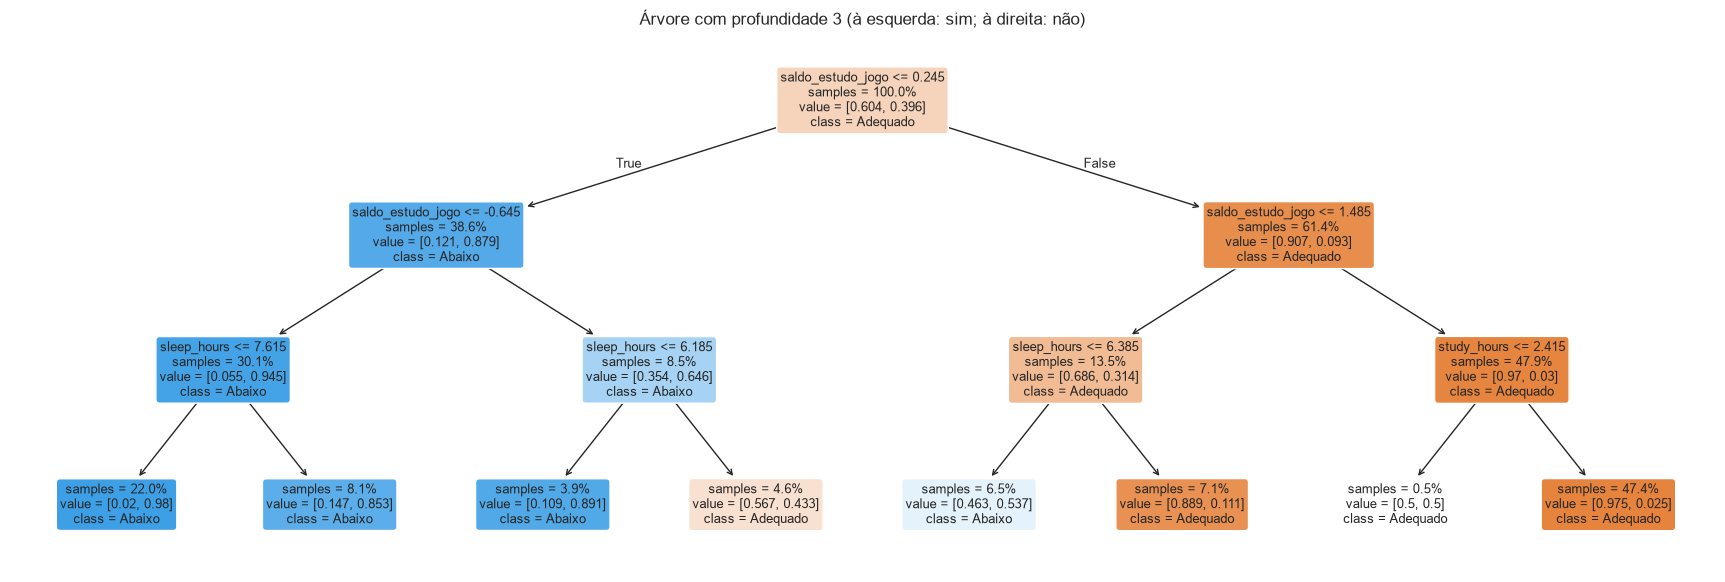

,acurácia,precisão,recall,alertas,VP,FN,custo
treino (ajuste),0.907,0.875,0.894,1799,1574,187,2734
validação,0.897,0.862,0.882,601,518,69,946


In [25]:
arv3 = arvore(3).fit(X_aj, y_aj)
nomes = list(arv3.named_steps['preparo'].get_feature_names_out())
plt.figure(figsize=(22, 7))
plot_tree(arv3.named_steps['modelo'], feature_names=nomes, class_names=['Adequado', CLASSE_POSITIVA], filled=True,
          rounded=True, proportion=True, impurity=False, fontsize=9)
plt.title('Árvore com profundidade 3 (à esquerda: sim; à direita: não)')
plt.show()
tabela({'treino (ajuste)': metricas(y_aj, arv3.predict(X_aj)), 'validação': metricas(y_val, arv3.predict(X_val))})

**Leitura.** A primeira pergunta é a mesma da regra simples (`saldo_estudo_jogo <= 0,24`) e a segunda também usa o
saldo. Só na terceira a árvore recorre a `sleep_hours`: entre quem está perto da linha de corte do saldo, dormir
menos de 6,2 horas empurra o estudante para o grupo de risco. É coerente com a EDA, onde `sono_insuficiente` elevava
a taxa de 33% para 48%.

Com profundidade 3 ela acerta 90,7% no ajuste e **89,7% na validação** — números próximos, sinal de que ainda há
espaço para crescer sem overfitting.

## 6.4 Complexidade: underfitting e overfitting

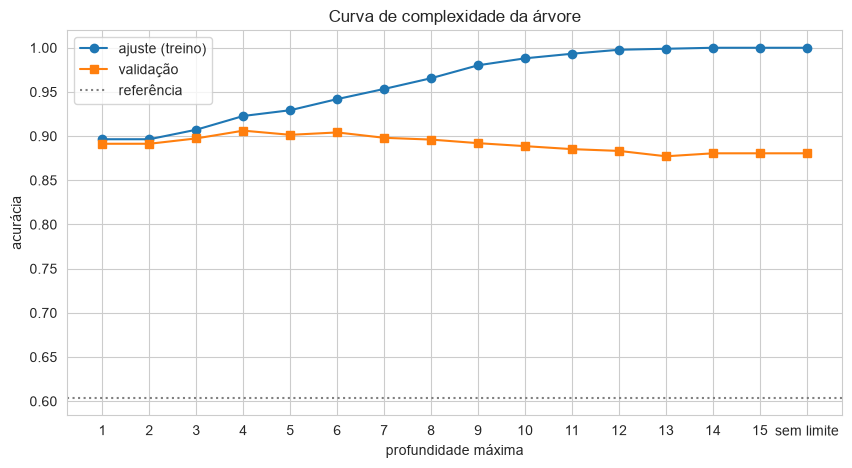

Profundidade com a melhor acurácia na validação: 4


,profundidade,folhas,acurácia ajuste,acurácia validação
0,1,2,0.896,0.891
2,3,8,0.907,0.897
3,4,16,0.923,0.906
9,10,227,0.988,0.889
15,sem limite,280,1.000,0.881


In [26]:
profundidades = list(range(1, 16)) + [None]
curva = []
for p in profundidades:
    m = arvore(p, min_folha=1).fit(X_aj, y_aj)
    curva.append({'profundidade': 'sem limite' if p is None else p, 'folhas': m.named_steps['modelo'].get_n_leaves(),
                  'acurácia ajuste': accuracy_score(y_aj, m.predict(X_aj)), 'acurácia validação': accuracy_score(y_val, m.predict(X_val))})
curva = pd.DataFrame(curva)
eixo = curva['profundidade'].astype(str)
plt.plot(eixo, curva['acurácia ajuste'], 'o-', label='ajuste (treino)')
plt.plot(eixo, curva['acurácia validação'], 's-', label='validação')
plt.axhline(max(y_val.mean(), 1 - y_val.mean()), color='gray', ls=':', label='referência')
plt.xlabel('profundidade máxima')
plt.ylabel('acurácia')
plt.title('Curva de complexidade da árvore')
plt.legend()
plt.show()

PROFUNDIDADE = int(curva.iloc[:-1].loc[curva.iloc[:-1]['acurácia validação'].idxmax(), 'profundidade'])
print(f'Profundidade com a melhor acurácia na validação: {PROFUNDIDADE}')
display(curva.iloc[sorted({0, 2, PROFUNDIDADE - 1, 9, len(curva) - 1})])

# Desafio 1: descomente a linha abaixo para usar, daqui em diante, uma árvore sem limite.
# PROFUNDIDADE, MIN_FOLHA = None, 1

**Leitura.** A curva repete o comportamento da aula 11:

- **Underfitting (profundidades 1 e 2):** as duas curvas colam (89,65% de ajuste contra 89,14% de validação).
  A árvore está simples demais, embora já bem acima da referência de 60,4%.
- **Ponto de equilíbrio (profundidade 4):** a melhor acurácia de validação, **90,62%**, com 16 folhas.
- **Overfitting (da profundidade 5 em diante):** o ajuste sobe até **100%** enquanto a validação **cai** — 89,2% na
  profundidade 9, 88,5% na 11 e **88,06%** sem limite. Sem limite a árvore cria 280 folhas e acerta todos os
  estudantes do ajuste, mas acerta **menos** nos que nunca viu.

A queda aqui é menos dramática que na base de exemplo da oficina porque a relação entre o saldo estudo-jogo e o alvo
é forte e quase determinística: mesmo decorando, a árvore ainda acerta a maior parte. Ainda assim, a conclusão é a
mesma — **decorar o treino não é aprender**, e a escolha se faz pela validação.

## 6.5 Limiar de decisão pelo custo dos erros

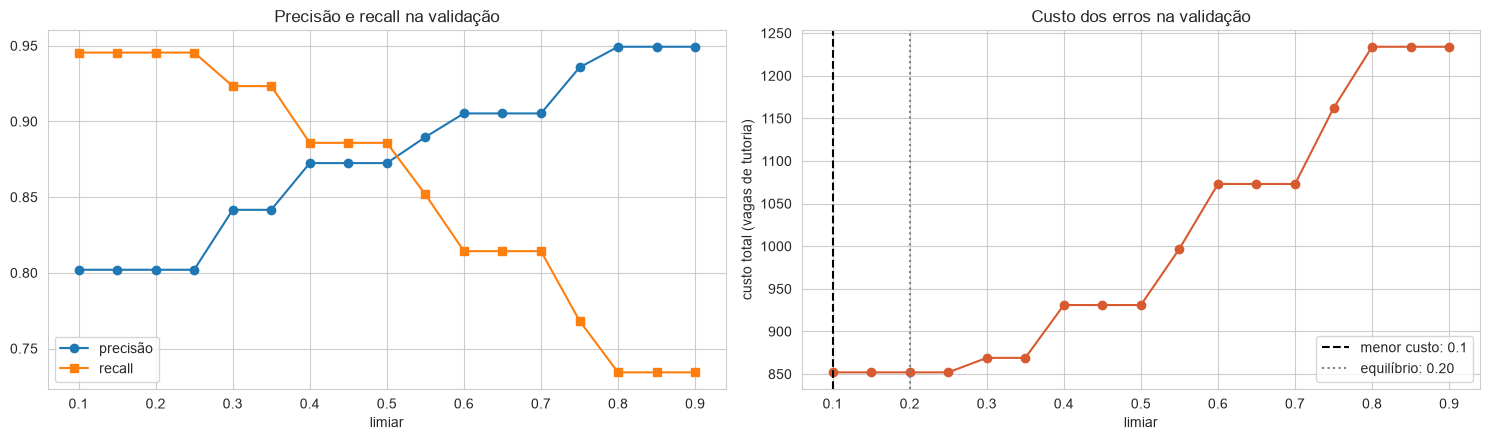

,limiar,acurácia,precisão,recall,alertas,VP,FN,custo
0,0.100,0.886,0.802,0.945,692,555,32,852
1,0.150,0.886,0.802,0.945,692,555,32,852
2,0.200,0.886,0.802,0.945,692,555,32,852
3,0.250,0.886,0.802,0.945,692,555,32,852
4,0.300,0.901,0.842,0.923,644,542,45,869
5,0.350,0.901,0.842,0.923,644,542,45,869
6,0.400,0.904,0.872,0.886,596,520,67,931
7,0.450,0.904,0.872,0.886,596,520,67,931
8,0.500,0.904,0.872,0.886,596,520,67,931
9,0.550,0.899,0.890,0.852,562,500,87,997


Limiar escolhido pelo menor custo: 0.1 | limiar de equilíbrio (CUSTO_ACAO / CUSTO_PERDA): 0.20


In [27]:
modelo_val = arvore(PROFUNDIDADE).fit(X_aj, y_aj)
risco_val = modelo_val.predict_proba(X_val)[:, 1]
limiares = np.round(np.arange(0.1, 0.91, 0.05), 2)
tab_limiar = pd.DataFrame([{'limiar': t, **metricas(y_val, (risco_val >= t).astype(int))} for t in limiares])
tab_limiar = tab_limiar.astype({'alertas': int, 'VP': int, 'FN': int, 'custo': int})
LIMIAR = float(tab_limiar.loc[tab_limiar['custo'].idxmin(), 'limiar'])

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(tab_limiar['limiar'], tab_limiar['precisão'], 'o-', label='precisão')
axes[0].plot(tab_limiar['limiar'], tab_limiar['recall'], 's-', label='recall')
axes[0].set(xlabel='limiar', title='Precisão e recall na validação')
axes[0].legend()
axes[1].plot(tab_limiar['limiar'], tab_limiar['custo'], 'o-', color='#D85A30')
axes[1].axvline(LIMIAR, color='black', ls='--', label=f'menor custo: {LIMIAR}')
axes[1].axvline(CUSTO_ACAO / CUSTO_PERDA, color='gray', ls=':', label=f'equilíbrio: {CUSTO_ACAO / CUSTO_PERDA:.2f}')
axes[1].set(xlabel='limiar', ylabel='custo total (vagas de tutoria)', title='Custo dos erros na validação')
axes[1].legend()
plt.tight_layout()
plt.show()
display(tab_limiar)
print(f'Limiar escolhido pelo menor custo: {LIMIAR} | limiar de equilíbrio (CUSTO_ACAO / CUSTO_PERDA): {CUSTO_ACAO / CUSTO_PERDA:.2f}')

**Leitura.** O gráfico mostra o balanço clássico: baixar o limiar aumenta o **recall** (de 73,4% em 0,90 para 94,5%
em 0,10) e reduz a **precisão** (de 94,9% para 80,2%). Com os custos definidos pelo grupo (1 para alertar, 5 para
perder), o menor custo na validação é **852 unidades**, no limiar **0,10** — bem abaixo do 0,5 padrão.

O resultado é coerente com o limiar de equilíbrio (1/5 = 0,20): como perder um estudante custa cinco vezes mais do
que acompanhar um a mais, compensa alertar sempre que o risco passar de 20% — e, na prática, a curva de custo fica
plana entre 0,10 e 0,25, porque a árvore de profundidade 4 produz poucos valores distintos de risco. Qualquer limiar
nessa faixa gera as mesmas 692 indicações e os mesmos 32 estudantes perdidos.

**Tradução para a decisão real:** com o limiar 0,5, o programa indicaria 596 estudantes e deixaria 67 sem apoio;
com o limiar 0,10, indica 692 e deixa 32. São 96 vagas a mais de tutoria para alcançar 35 estudantes em risco a mais.
Pelos custos adotados, vale a pena.

# 7. Avaliação final no teste

,acurácia,precisão,recall,alertas,VP,FN,custo
referência,0.604,0.000,0.000,0,0,783,3915
"regra de uma pergunta, limiar 0.1",0.897,0.878,0.858,765,672,111,1320
"árvore, limiar 0,5",0.916,0.878,0.916,817,717,66,1147
"árvore, limiar 0.1",0.890,0.805,0.953,927,746,37,1112
alertar todos,0.396,0.396,1.000,1976,783,0,1976


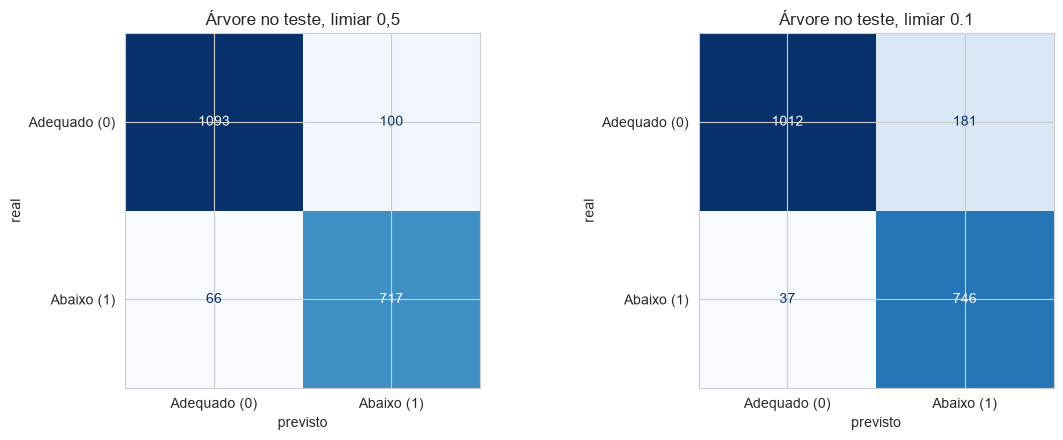

In [28]:
final = arvore(PROFUNDIDADE).fit(X_treino, y_treino)
referencia_final = Pipeline([('preparo', criar_preparo()), ('modelo', DummyClassifier(strategy='most_frequent'))]).fit(X_treino, y_treino)
regra_final = arvore(1).fit(X_treino, y_treino)
risco_teste = final.predict_proba(X_teste)[:, 1]
prev_teste = (risco_teste >= LIMIAR).astype(int)

resultado = tabela({
    'referência': metricas(y_teste, referencia_final.predict(X_teste)),
    f'regra de uma pergunta, limiar {LIMIAR}': metricas(y_teste, (regra_final.predict_proba(X_teste)[:, 1] >= LIMIAR).astype(int)),
    'árvore, limiar 0,5': metricas(y_teste, (risco_teste >= 0.5).astype(int)),
    f'árvore, limiar {LIMIAR}': metricas(y_teste, prev_teste),
    'alertar todos': metricas(y_teste, np.ones(len(y_teste), dtype=int)),
})
display(resultado)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (rot, prev) in zip(axes, [('limiar 0,5', (risco_teste >= 0.5).astype(int)), (f'limiar {LIMIAR}', prev_teste)]):
    disp = ConfusionMatrixDisplay(confusion_matrix(y_teste, prev), display_labels=['Adequado (0)', f'{CLASSE_POSITIVA} (1)'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set(title=f'Árvore no teste, {rot}', xlabel='previsto', ylabel='real')
plt.tight_layout()
plt.show()

Na matriz do Scikit-learn, o real está nas linhas e o previsto nas colunas, com a classe 0 primeiro: canto superior
esquerdo são os verdadeiros negativos, inferior direito os verdadeiros positivos, superior direito os falsos
positivos (alertas desnecessários) e inferior esquerdo os falsos negativos (estudantes em risco não detectados).

**Leitura.** No teste — 1.976 estudantes que nenhum modelo tinha visto, dos quais 783 ficaram abaixo de 60:

| Modelo | Acurácia | Precisão | Recall | Indicações | Não detectados | Custo |
|---|---|---|---|---|---|---|
| referência | 60,4% | 0% | **0%** | 0 | 783 | 3.915 |
| regra de uma pergunta | 89,7% | 87,8% | 85,8% | 765 | 111 | 1.320 |
| árvore, limiar 0,5 | **91,6%** | 87,8% | 91,6% | 817 | 66 | 1.147 |
| **árvore, limiar 0,10** | 89,0% | 80,5% | **95,3%** | 927 | **37** | **1.112** |
| alertar todos | 39,6% | 39,6% | 100% | 1.976 | 0 | 1.976 |

A árvore com o limiar escolhido encontra **95,3% dos estudantes em risco** e tem o **menor custo** (1.112 contra
3.915 da referência: **72% menos**). Repare que ela tem acurácia **menor** que a árvore com limiar 0,5 (89,0% contra
91,6%) e mesmo assim é a melhor escolha — porque troca 110 alertas a mais por 29 estudantes resgatados, e cada
estudante resgatado vale cinco alertas. **É o exemplo de por que a acurácia não decide sozinha.**

Comparando com a validação: recall de 94,5% lá e 95,3% aqui, acurácia de 88,6% e 89,0%. Os números quase não mudam —
**não houve overfitting na escolha do modelo nem do limiar**.

# 8. Análise de erros e interpretação

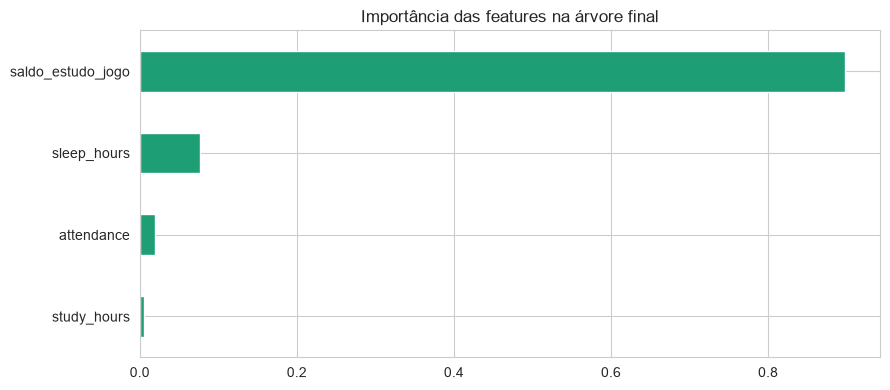

,importância
saldo_estudo_jogo,0.898
sleep_hours,0.077
attendance,0.020
study_hours,0.006


Features com importância zero: ['age', 'gaming_hours', 'social_activity', 'device_usage', 'reaction_time_ms', 'addiction_score', 'gender_Female', 'gender_Male', 'gender_Other', 'gaming_genre_Casual', 'gaming_genre_FPS', 'gaming_genre_RPG', 'stress_level_High', 'stress_level_Low', 'stress_level_Medium', 'faixa_jogo_excessivo (+5h)', 'faixa_jogo_leve (até 2h)', 'faixa_jogo_moderado (2h a 5h)', 'jogo_alto_estudo_baixo_não', 'jogo_alto_estudo_baixo_sim', 'sono_insuficiente_não', 'sono_insuficiente_sim']


In [29]:
imp = pd.Series(final.named_steps['modelo'].feature_importances_, index=final.named_steps['preparo'].get_feature_names_out())
imp_pos = imp[imp > 0].sort_values()
imp_pos.plot.barh(color='#1D9E75', figsize=(9, 4), title='Importância das features na árvore final')
plt.tight_layout()
plt.show()
display(imp_pos.sort_values(ascending=False).round(3).to_frame('importância'))
print('Features com importância zero:', list(imp[imp == 0].index))

**Leitura.** A árvore final usa **quatro** das 26 colunas disponíveis:

| Feature | Importância |
|---|---|
| `saldo_estudo_jogo` | **89,8%** |
| `sleep_hours` | 7,7% |
| `attendance` | 2,0% |
| `study_hours` | 0,6% |

Tudo o mais fica em zero — inclusive `gaming_hours`, `addiction_score`, `device_usage`, `reaction_time_ms`,
`stress_level`, `faixa_jogo` e `jogo_alto_estudo_baixo`. Isso **não** significa que essas variáveis sejam
irrelevantes: significa que `saldo_estudo_jogo`, que foi construída a partir das duas mais fortes, já carrega a
informação delas. É a confirmação prática da redundância diagnosticada em 3.7 — das quatro medidas de "quanto joga",
a árvore precisou de nenhuma depois de ter o saldo.

Também é a confirmação de que o modelo **não usa `stress_level`**, o que é um bom sinal: como mostrou a seção 3.6,
usar estresse declarado como critério de triagem levaria a chamar os estudantes errados.

## 8.2 Onde a árvore erra

In [30]:
erros = X_teste.assign(real=y_teste.values, previsto=prev_teste, risco=risco_teste.round(2))
erros['FN (estudante perdido)'] = (erros['real'] == 1) & (erros['previsto'] == 0)
erros['FP (indicação desnecessária)'] = (erros['real'] == 0) & (erros['previsto'] == 1)
for c in list(amplitude.index[:2]) + ['faixa_jogo']:
    display(erros.groupby(c, observed=True).agg(n=('real', 'size'), em_risco=('real', 'sum'), indicados=('previsto', 'sum'),
                                                FN=('FN (estudante perdido)', 'sum'), FP=('FP (indicação desnecessária)', 'sum')))

# A que distância da nota de corte estão os erros? (usa grades só para analisar, nunca para prever)
notas = df.loc[erros.index, 'grades']
print(f'Nota real dos {int(erros["FN (estudante perdido)"].sum())} estudantes perdidos (FN): '
      f'média {notas[erros["FN (estudante perdido)"]].mean():.1f}, mediana {notas[erros["FN (estudante perdido)"]].median():.1f}')
print(f'Nota real das {int(erros["FP (indicação desnecessária)"].sum())} indicações desnecessárias (FP): '
      f'média {notas[erros["FP (indicação desnecessária)"]].mean():.1f}, mediana {notas[erros["FP (indicação desnecessária)"]].median():.1f}')
print('\nExemplos de estudantes perdidos (FN):')
erros[erros['FN (estudante perdido)']].head(5)[['gaming_hours', 'study_hours', 'sleep_hours', 'attendance',
                                                'stress_level', 'saldo_estudo_jogo', 'faixa_jogo', 'risco']]

,n,em_risco,indicados,FN,FP
stress_level,,,,,
High,231,19,42,3,26
Low,663,485,538,2,55
Medium,1082,279,347,32,100


,n,em_risco,indicados,FN,FP
gender,,,,,
Female,938,346,402,18,74
Male,969,401,485,19,103
Other,69,36,40,0,4


,n,em_risco,indicados,FN,FP
faixa_jogo,,,,,
excessivo (+5h),762,503,580,4,81
leve (até 2h),478,45,68,13,36
moderado (2h a 5h),736,235,279,20,64


Nota real dos 37 estudantes perdidos (FN): média 55.7, mediana 57.5
Nota real das 181 indicações desnecessárias (FP): média 66.2, mediana 65.3

Exemplos de estudantes perdidos (FN):


,gaming_hours,study_hours,sleep_hours,attendance,stress_level,saldo_estudo_jogo,faixa_jogo,risco
4581,3.270,3.900,6.860,71.510,Medium,0.630,moderado (2h a 5h),0.080
143,7.390,8.920,4.240,61.350,High,1.530,excessivo (+5h),0.100
2996,3.340,6.450,4.930,67.890,Medium,3.110,moderado (2h a 5h),0.010
7205,3.480,3.760,6.660,67.940,Medium,0.280,moderado (2h a 5h),0.080
2315,0.210,1.500,6.420,66.550,Medium,1.290,leve (até 2h),0.080


**Leitura.** Os erros se concentram **em torno da linha de corte**, que é o melhor cenário possível:

- Os **37 estudantes perdidos** (FN) tinham nota média **55,7** e mediana **57,5** — quase todos entre 55 e 60, isto é,
  a dois ou três pontos da aprovação. O modelo não deixou de ver ninguém em situação grave.
- As **181 indicações desnecessárias** (FP) tinham nota média **66,2** e mediana **65,3** — estudantes que passaram,
  mas por pouco. Chamá-los para acompanhamento é um "erro" barato e, na prática, provavelmente útil.

Por subgrupo:

- Por `stress_level`: dos 37 perdidos, 32 estão no grupo `Medium`, 3 no `High` e apenas 2 no `Low`. O grupo de
  estresse baixo — o de maior risco — é praticamente todo capturado (538 indicações para 485 estudantes em risco).
- Por `faixa_jogo`: entre os de jogo excessivo, o modelo perde apenas **4 de 503** estudantes em risco. As falhas se
  concentram em jogo leve (13 de 45) e moderado (20 de 235) — estudantes que ficam abaixo da nota de corte **sem**
  jogar muito, cujo motivo a base não registra.
- Por `gender`: 18 perdidos entre mulheres e 19 entre homens, em grupos de tamanho semelhante — o modelo **não falha
  mais para um gênero do que para outro**, o que é essencial em um sistema que decide quem recebe apoio institucional.

O padrão dos perdidos é claro nos exemplos: saldo de estudo positivo mas pequeno (0,28 a 3,11 horas) e risco estimado
entre 0,01 e 0,10. São estudantes que, pelos dados, pareciam estar bem — e ficaram pouco abaixo da linha.

# 9. Conclusões

1. **O alvo foi construído, não encontrado.** A base não traz "aprovado/reprovado": o grupo definiu o corte em 60
   pontos, o que produz 39,6% de estudantes em risco. `grades` precisou sair das features, e a seção 5.3 confirma
   por quê — sozinha, ela acerta 100%.
2. **Uma variável criada resolve quase todo o problema.** `saldo_estudo_jogo` (`study_hours − gaming_hours`) concentra
   **89,8%** da importância da árvore. A regra "estuda pelo menos 0,24h a mais do que joga?" sozinha já atinge 85,8%
   de recall no teste.
3. **O modelo escolhido generalizou.** Árvore de profundidade 4 com limiar 0,10: recall de 94,5% na validação e
   **95,3% no teste**, custo 72% abaixo da referência. Validação e teste praticamente iguais.
4. **O limiar importa mais que o modelo.** Mudar o limiar de 0,5 para 0,10 reduziu de 66 para 37 os estudantes em
   risco não detectados, ao preço de 110 indicações a mais — uma troca vantajosa pelos custos adotados, apesar de
   **reduzir** a acurácia de 91,6% para 89,0%.
5. **Quatro variáveis medem a mesma coisa.** `gaming_hours`, `device_usage`, `addiction_score` e `reaction_time_ms`
   têm correlação de 0,79 a 0,94 entre si; a árvore não precisou de nenhuma delas depois do saldo estudo-jogo.
6. **O estresse declarado é uma armadilha de triagem.** Estudantes com estresse baixo têm 72,4% de risco e os de
   estresse alto, 6,8% — porque estresse alto marca quem estuda muito. Um programa que chamasse "os mais estressados"
   atenderia exatamente o grupo errado. Era a dúvida deixada em aberto pela AV1.
7. **Não há um "ponto de virada" nas horas de jogo.** O risco cresce de forma contínua: 10,3% (até 2h), 32,1%
   (2h a 5h), 65,4% (mais de 5h). O grupo crítico é definido pela combinação: 98,5% dos que jogam mais de 5h **e**
   estudam menos de 4h ficam abaixo do corte.
8. **Os erros são benignos e equilibrados.** Os não detectados tinham nota média 55,7 (perto da linha) e as
   indicações desnecessárias, 66,2. Não há diferença de desempenho entre gêneros.

## Decisão: **Investigar**

O modelo passa em todos os critérios técnicos de "Aplicar": o alvo existe e é bem definido, as features são conhecidas
no início do semestre, a verificação de vazamento está limpa depois da exclusão de `grades`, o modelo supera a
referência com folga (recall de 95,3% contra 0%) e validação e teste ficam a menos de um ponto percentual.

O que impede a aplicação não é o modelo, é a **origem dos dados**. A base é declaradamente simulada, e três evidências
deste notebook confirmam: distribuições uniformes com cortes exatos, zero outliers pela regra do IQR e um bloco de
quatro variáveis com correlação de até 0,94 entre si. Um recall de 95% mede a qualidade do gerador dos dados, não a
dificuldade real de antecipar o desempenho de um estudante. Há ainda duas limitações próprias do problema:
`gaming_hours` e `study_hours` seriam **autodeclaradas** em uma coleta real, e a base não registra nada sobre
dificuldade das disciplinas, condição socioeconômica ou trabalho — justamente o que explicaria os estudantes de jogo
leve que ficam abaixo do corte.

**O que falta para mudar a decisão para "Aplicar":**

1. Coletar dados reais de uma turma, com horas de estudo e de jogo registradas **no início** do semestre;
2. Confirmar a nota de corte com a coordenação do curso (o parâmetro `NOTA_DE_CORTE` já isola essa escolha);
3. Validar os custos de 1 e 5 com quem administra o programa de tutoria, já que é essa razão que define o limiar;
4. Repetir este notebook sobre esses dados e comparar o recall com o da referência.

Enquanto isso, há um resultado deste notebook que **já pode ser usado sem modelo nenhum**: os estudantes que jogam
mais de 5h por dia e estudam menos de 4h têm 98,5% de chance de ficar abaixo de 60. São 13,5% da base, um grupo de
tamanho administrável, identificável com duas perguntas em um formulário de matrícula.

# 10. Desafios

Respondidos com os números da **base de exemplo da oficina** (`Telco-Customer-Churn.csv`, cancelamento de clientes),
como pede o enunciado. Cada alteração foi feita, executada e depois desfeita.

### 1. Complexidade

Na curva de 6.4 da base de exemplo, a árvore **sem limite** tem **781 folhas**, acurácia de ajuste **99,8%** e
acurácia de validação **72,8%** — abaixo até da referência (73,4%). A árvore escolhida, de profundidade 3, tem
8 folhas, 79,1% de ajuste e 79,5% de validação.

Descomentando `PROFUNDIDADE, MIN_FOLHA = None, 1` e rodando tudo (o limiar escolhido muda de 0,30 para 0,35):

| No teste | Acurácia | Recall | Alertas | FN | Custo |
|---|---|---|---|---|---|
| árvore profundidade 3, limiar 0,30 (original) | 75,1% | **75,6%** | 677 | 114 | **56.650** |
| árvore sem limite, limiar 0,35 | 73,7% | 50,5% | 468 | 231 | 69.600 |

A árvore sem limite é **pior nos três critérios**: perde 1,4 ponto de acurácia, **25 pontos de recall** (deixa de
detectar 117 cancelamentos a mais) e custa 12.950 USD a mais.

Com 99,8% de acerto no ajuste e 72,8% na validação, a árvore sem limite **decorou** os clientes em vez de aprender o
padrão: 781 folhas para 3.962 clientes de ajuste. Essa distância entre ajuste e validação é a definição de
**overfitting**. **Generalização** é o contrário — ir bem em dados nunca vistos —, e é por isso que a profundidade é
escolhida pela validação, nunca pelo ajuste. O caso é ainda mais eloquente que o da regressão: aqui a árvore decorada
fica **abaixo da referência** na validação.

### 2. Custo e limiar

Mantendo `CUSTO_PERDA = 200` e variando `CUSTO_ACAO`:

| `CUSTO_ACAO` | Equilíbrio (ação/perda) | Limiar escolhido | Alertas no teste | Recall | FN |
|---|---|---|---|---|---|
| 20 | 0,10 | **0,10** | 1.061 | **93,6%** | 30 |
| 50 (original) | 0,25 | 0,30 | 677 | 75,6% | 114 |
| 150 | 0,75 | **0,75** | **0** | **0%** | 467 |

O limiar escolhido **acompanha o limiar de equilíbrio** em todos os casos, e a explicação é direta: vale a pena
alertar um cliente quando o risco estimado multiplicado pelo custo da perda supera o custo da ação, ou seja, quando
`risco × CUSTO_PERDA > CUSTO_ACAO` — isto é, quando `risco > CUSTO_ACAO / CUSTO_PERDA`. Esse quociente **é** o limiar
de equilíbrio.

- Com `CUSTO_ACAO = 20`, o desconto é barato: compensa alertar qualquer cliente com mais de 10% de risco. Os alertas
  sobem para 1.061 (60% da base de teste) e o recall vai a 93,6%.
- Com `CUSTO_ACAO = 150`, o desconto custa quase o mesmo que perder o cliente (150 contra 200). O limiar de 0,75 fica
  acima do risco máximo que a árvore atribui a qualquer cliente, então **o modelo deixa de alertar qualquer um** e se
  iguala à referência. A leitura de negócio é clara: **com esse custo, o programa de retenção não se paga** — o
  problema não é o modelo, é a ação proposta.

### 3. Vazamento

Na base de exemplo, `motivo_saida` acerta **100,0%** sozinha (26,6 pontos acima da referência de 73,4%) e é marcada
como POSSÍVEL VAZAMENTO. Nenhuma feature real passa de 75,4% (`tenure`).

A razão é **cronológica**: o motivo da saída só é preenchido **depois** que o cliente cancela. No momento em que a
previsão precisa ser feita — com o cliente ainda ativo — essa coluna está vazia para todo mundo. Um modelo treinado
com ela teria 100% de acurácia no notebook e serviria para nada na prática: ele só sabe responder depois que a
resposta já é conhecida. A regra geral é que toda feature precisa existir **no instante em que a decisão é tomada**.

**No projeto do grupo** há um caso idêntico, e ele é central: a coluna **`grades`**. Como o alvo (`desempenho`) é
construído a partir dela, mantê-la entre as features daria 100% de acerto — exatamente o que a seção 5.3 deste
notebook demonstra. Pelo mesmo motivo entrariam na lista: a situação final (aprovado/reprovado), a nota de um
bimestre posterior, a frequência fechada no fim do semestre e o registro de encaminhamento ao reforço.

### 4. Features

A feature mais importante em 8.1 da base de exemplo é `Contract_Month-to-month` (59,8% da importância).
Acrescentando `'Contract'` a `COLUNAS_FORA` e rodando tudo (a profundidade escolhida cai de 3 para 2 e o limiar de
0,30 para 0,10):

| No teste | Recall | Precisão | Alertas | Custo |
|---|---|---|---|---|
| com `Contract` (original) | 75,6% | 52,1% | 677 | **56.650** |
| sem `Contract` | **89,1%** | **39,4%** | 1.056 | **63.000** |

O **custo piora 6.350 USD (+11,2%)**, mas o recall **sobe** de 75,6% para 89,1%. Isso parece contraditório e não é:
sem `Contract`, o modelo fica menos capaz de distinguir quem cancela, e a escolha por menor custo compensa a
incerteza **alertando muito mais gente** (1.056 contra 677). Ele encontra mais cancelamentos porque atira mais —
a precisão cai de 52,1% para 39,4%, e são esses alertas desperdiçados que encarecem a operação. O recall sozinho
pode enganar; é por isso que a oficina avalia pelo custo.

**A árvore encontrou substitutos.** Sem `Contract`, a importância se redistribui entre `InternetService_Fiber optic`
(50,4%) e `tenure` (49,6%), que antes somavam 36,8%. São variáveis correlacionadas com o tipo de contrato (clientes
de fibra e clientes novos tendem ao contrato mensal), então parte do sinal é recuperada — mas só parte, como mostra
a queda de 12,7 pontos na precisão.

### 5. Referência

Sim, a regra de uma pergunta já supera a referência com folga. No teste da base de exemplo:

| Modelo | Recall | Custo | Alertas |
|---|---|---|---|
| referência (prever "não cancela") | **0%** | 93.400 | 0 |
| regra de uma pergunta, limiar 0,30 | **88,7%** | 59.000 | 968 |
| árvore (profundidade 3), limiar 0,30 | 75,6% | **56.650** | 677 |

A regra de uma pergunta ("o contrato é mensal?") sozinha já captura 88,7% dos cancelamentos e reduz o custo em 36,8%
em relação à referência. A árvore acrescenta a isso **2.350 USD de economia (4,0%)** — e, curiosamente, com recall
**13,1 pontos menor**: ela é mais seletiva, emite 291 alertas a menos e troca cancelamentos detectados por descontos
economizados.

**Vale a complexidade a mais?** Neste caso, **é discutível e a resposta depende do objetivo**. Se o critério for
estritamente o custo modelado, a árvore vence por 4% — uma margem pequena para um modelo com 8 folhas contra uma
pergunta que cabe em uma frase. Se o objetivo for reter o máximo de clientes (recall), a regra simples é melhor.
E a regra tem duas vantagens práticas: é auditável por qualquer pessoa da área comercial e não precisa de
retreinamento. A recomendação honesta seria **começar pela regra de uma pergunta** e só adotar a árvore se a
diferença de 4% se confirmar em produção — ou se os custos forem recalibrados e a diferença crescer.

# 11. Entrega: o que foi adaptado

Este notebook é a cópia do `oficina_ML_classificacao.ipynb` adaptada à base do projeto. O que mudou em relação ao original:

| Seção | Alteração |
|---|---|
| 0. Parâmetros | `ALVO = 'desempenho'` (criado a partir de `grades`), `CLASSE_POSITIVA = 'Abaixo'`, `NOTA_DE_CORTE = 60`, `COLUNAS_FORA = ['student_id', 'grades']`, custos redefinidos em vagas de tutoria (1 e 5) e carregamento do CSV local do projeto |
| 1.2 Faixas de validade | Regras do domínio da base do projeto, no lugar da checagem de `TotalCharges` em branco (célula "específica da base de exemplo", apagada) |
| 1.3 `limpar` | As três regras definidas na AV1 (limitar `grades` a 100, limitar `addiction_score` a 0, remover dias de mais de 24h) **e a construção do alvo binário** a partir da nota de corte |
| 3.2, 3.3 e 3.5 | Grades de gráficos reorganizadas para as nove numéricas e as três categóricas da base |
| 3.6 | Mostra as três categóricas (a base de exemplo tinha 16 e exibia só as quatro maiores) |
| 3.7 | Acrescentada a tabela cruzada de `stress_level` por faixa de `study_hours`, para investigar o achado contraintuitivo da AV1 |
| 4.1 `criar_atributos` | Quatro variáveis novas, as mesmas do notebook de regressão: `faixa_jogo`, `saldo_estudo_jogo`, `jogo_alto_estudo_baixo` e `sono_insuficiente` |
| 5.3 | A coluna de vazamento deixou de ser fictícia: usa `grades`, a coluna real que gerou o alvo |
| 5.4 | Teste de robustez com `study_hours` ausente e a categoria inexistente `stress_level = 'Extremo'` |
| 6.5 | Acrescentada a tabela completa de limiares e a leitura dos resultados em vagas de tutoria |
| 8.1 | Acrescentada a lista de features com importância zero |
| 8.2 | Análise de erro também por `faixa_jogo` e pela distância entre a nota real e a nota de corte |
| Textos | Todas as células **Leitura**, a síntese 3.8 e as conclusões da seção 9 foram reescritas com os números da base do projeto |
| 10 | Desafios respondidos com os números da base de exemplo, como pede o enunciado |

**Arquivos do projeto:**

- `Analise_GrupoGamingvsAcademicPerformance.ipynb` — preparação e EDA (AV1)
- `oficina_ML_Regressao_GrupoGamingvsAcademicPerformance.ipynb` — previsão da nota
- `oficina_ML_Classificacao_GrupoGamingvsAcademicPerformance.ipynb` — este notebook
- `dados/Base_Original_GrupoGamingvsAcademicPerformance.csv` — base usada aqui